# PhysioNet 2019 ICU data: download and exploratory data analysis

This notebook downloads the public training data of the PhysioNet/Computing in Cardiology Challenge 2019 and summarizes:

1. **Dataset size**: patients, patient-hours, length of stay, sepsis prevalence (set A vs set B)
2. **Feature dictionary**: all 40 variables with units, and which ones we propose to use
3. **Missing data**: missingness per variable, set A vs B, by hour since ICU admission, which labs are measured together, and how often each variable is measured
4. **Distributions**: summary statistics, implausible values, skewness (which labs to log-transform)
5. **Target (MAP)**: hypotension rates, within-patient correlation (motivates the random effect and the AR(1) covariance), and how many 6-hour forecast windows we will have

**How to run**

- Edit the settings in the first code cell (mainly `DATA_DIR`), then run all cells.
- Works on Windows, macOS and Linux. Needs `pandas`, `numpy` and `matplotlib` (`scipy` is optional).
- The download is about 40,000 small files. On Great Lakes, run the download on a login node (compute nodes may not have internet), then run the analysis anywhere.
- Every table is saved as `.csv` and every figure as `.png` in `OUT_DIR`.

In [1]:
%matplotlib inline
import re, time, shutil, subprocess, urllib.request, json
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ---------------- Settings you may want to change ----------------
DATA_DIR = Path("/scratch/kinfai_root/kinfai0/mhanyu/biostats664/final_proj/datasets")   # files go to DATA_DIR/training/training_setA and training_setB
OUT_DIR = Path("/scratch/kinfai_root/kinfai0/mhanyu/biostats664/final_proj/EDA")      # tables (.csv) and figures (.png) are saved here
DOWNLOAD = True                    # set False if the .psv files are already in DATA_DIR
DOWNLOAD_METHOD = "auto"           # "auto", "aws", "wget" or "python"
N_THREADS = 8                      # parallel downloads / file reads
MISSING_CUTOFF = 0.95              # flag variables missing in more than this share of patient-hours
HORIZON = 6                        # forecast horizon (hours)
THRESHOLDS = (65, 60)              # MAP thresholds (mmHg)
SEED = 2026
# -----------------------------------------------------------------

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.2.6


In [2]:
# Plot style (validated categorical palette; one hue per feature group)
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GROUP_COLORS = {"Vital sign": SERIES[0], "Laboratory": SERIES[1], "Demographic/time": SERIES[2]}
BLUE_SEQ = LinearSegmentedColormap.from_list(
    "blue_seq", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"])
BLUE_RED = LinearSegmentedColormap.from_list(
    "blue_red", ["#104281", "#3987e5", "#f0efec", "#e66767", "#b32d2d"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "lines.linewidth": 2, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.prop_cycle": plt.cycler(color=SERIES),
})

def finish(fig, name):
    """Tidy layout, save to OUT_DIR as PNG, and show."""
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"{name}.png")
    plt.show()

def save_table(table, name):
    table.to_csv(OUT_DIR / f"{name}.csv")
    return table

## 1. Download

The data are open access (CC BY 4.0). Four ways to get them, chosen automatically with `DOWNLOAD_METHOD = "auto"`:

| Method | When it is used | Notes |
|---|---|---|
| `aws` | AWS CLI installed | Fastest: `aws s3 sync --no-sign-request s3://physionet-open/challenge-2019/1.0.0/training/ ...` |
| `wget` | `wget` installed (Linux, Great Lakes) | `wget -r -N -c -np https://physionet.org/files/challenge-2019/1.0.0/training/` |
| `python` | Otherwise (e.g., Windows) | Pure Python; downloads the ~40,000 files in parallel. Re-running resumes where it stopped. |
| manual | If all else fails | Download from the [PhysioNet project page](https://physionet.org/content/challenge-2019/1.0.0/) and unzip into `DATA_DIR`, then set `DOWNLOAD = False` |

The download is skipped if the files are already there.

## 2. Load all patients into one table

Each `.psv` file is one patient; each row is one hour in the ICU. We add `patient_id`, `set` (A or B) and `hour` (0, 1, 2, ... within the stay). The combined table is cached as a pickle so later runs load in seconds.

In [3]:
VITALS = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2"]
LABS = ["BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2", "AST", "BUN", "Alkalinephos", "Calcium",
        "Chloride", "Creatinine", "Bilirubin_direct", "Glucose", "Lactate", "Magnesium", "Phosphate",
        "Potassium", "Bilirubin_total", "TroponinI", "Hct", "Hgb", "PTT", "WBC", "Fibrinogen", "Platelets"]
DEMO = ["Age", "Gender", "Unit1", "Unit2", "HospAdmTime", "ICULOS"]
OUTCOME = "SepsisLabel"
FEATURES = VITALS + LABS + DEMO
CACHE = DATA_DIR / "physionet2019_all.pkl"

def infer_set(path):
    s = str(path)
    if "setA" in s:
        return "A"
    if "setB" in s:
        return "B"
    return "A" if int(re.sub(r"\D", "", path.stem)) < 100000 else "B"

def read_one(path):
    d = pd.read_csv(path, sep="|")
    d.insert(0, "patient_id", path.stem)
    d.insert(1, "set", infer_set(path))
    d.insert(2, "hour", np.arange(len(d), dtype=np.int32))
    return d

if CACHE.exists():
    df = pd.read_pickle(CACHE)
    print("Loaded cached table:", CACHE)
else:
    files = sorted(DATA_DIR.rglob("*.psv"))
    if not files:
        raise FileNotFoundError(f"No .psv files under {DATA_DIR.resolve()}")
    print(f"Reading {len(files):,} files ...")
    t0 = time.time()
    with ThreadPoolExecutor(N_THREADS) as ex:
        parts = list(ex.map(read_one, files))
    df = pd.concat(parts, ignore_index=True)
    float_cols = df.select_dtypes("float64").columns
    df[float_cols] = df[float_cols].astype("float32")
    df = df.sort_values(["patient_id", "hour"]).reset_index(drop=True)
    df.to_pickle(CACHE)
    print(f"Read in {time.time() - t0:.0f} s; cached to {CACHE}")

missing_cols = [c for c in FEATURES + [OUTCOME] if c not in df.columns]
assert not missing_cols, f"Unexpected file format, missing columns: {missing_cols}"
print(f"{df.shape[0]:,} patient-hours x {df.shape[1]} columns; "
      f"{df.memory_usage(deep=True).sum() / 1e9:.2f} GB in memory")
df.head()

Loaded cached table: /scratch/kinfai_root/kinfai0/mhanyu/biostats664/final_proj/datasets/physionet2019_all.pkl
1,552,210 patient-hours x 44 columns; 0.47 GB in memory


,patient_id,set,hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,...,WBC,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel
0,p000001,A,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,1,0
1,p000001,A,1,97.00,95.00,NaN,98.00,75.33,NaN,19.00,...,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,2,0
2,p000001,A,2,89.00,99.00,NaN,122.00,86.00,NaN,22.00,...,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,3,0
3,p000001,A,3,90.00,95.00,NaN,NaN,NaN,NaN,30.00,...,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,4,0
4,p000001,A,4,103.00,88.50,NaN,122.00,91.33,NaN,24.50,...,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,5,0


## 3. Dataset size

In [4]:
stay = df.groupby("patient_id").agg(set=("set", "first"), hours=("hour", "size"),
                                     sepsis=(OUTCOME, "max"), age=("Age", "first"))

def size_row(s):
    return pd.Series({"patients": len(s), "patient_hours": s["hours"].sum(),
                      "mean_hours": s["hours"].mean(), "median_hours": s["hours"].median(),
                      "p25_hours": s["hours"].quantile(0.25), "p75_hours": s["hours"].quantile(0.75),
                      "max_hours": s["hours"].max(), "sepsis_patients": s["sepsis"].sum(),
                      "sepsis_pct": 100 * s["sepsis"].mean()})

overview = pd.DataFrame({f"Set {k}": size_row(v) for k, v in stay.groupby("set")})
overview["All"] = size_row(stay)
save_table(overview, "01_dataset_size")
display(overview)

same = (df["ICULOS"] == df["hour"] + 1).mean()
print(f"ICULOS equals row index + 1 in {100 * same:.1f}% of rows "
      f"(if not ~100%, some stays do not start at ICU admission).")

,Set A,Set B,All
patients,"20,336.00","20,000.00","40,336.00"
patient_hours,"790,215.00","761,995.00","1,552,210.00"
mean_hours,38.86,38.10,38.48
median_hours,39.00,38.00,38.00
p25_hours,25.00,23.00,24.00
p75_hours,47.00,47.00,47.00
max_hours,336.00,336.00,336.00
sepsis_patients,"1,790.00","1,142.00","2,932.00"
sepsis_pct,8.80,5.71,7.27


ICULOS equals row index + 1 in 78.8% of rows (if not ~100%, some stays do not start at ICU admission).


In [5]:
first = df.groupby("patient_id")["ICULOS"].first()
print("Distribution of ICULOS in each patient's first row:")
print(first.value_counts().sort_index().head(10))
print(f"Share of patients whose record does not start at ICULOS = 1: {(first != 1).mean():.1%}")

step = df.groupby("patient_id")["ICULOS"].diff().dropna()
print("\nDifference in ICULOS between consecutive rows:")
print(step.value_counts().head(10))

Distribution of ICULOS in each patient's first row:
ICULOS
1     31543
2      4129
3      1897
4      1149
5       653
6       423
7       233
8       123
9        67
10       32
Name: count, dtype: int64
Share of patients whose record does not start at ICULOS = 1: 21.8%

Difference in ICULOS between consecutive rows:
ICULOS
1.00    1511874
Name: count, dtype: int64


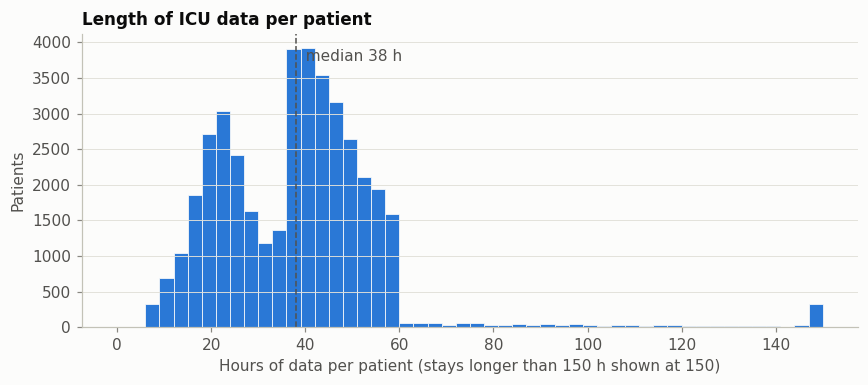

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
cap = 150
ax.hist(stay["hours"].clip(upper=cap), bins=np.arange(0, cap + 3, 3), color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
med = stay["hours"].median()
ax.axvline(med, color=INK2, lw=1, ls="--")
ax.text(med, ax.get_ylim()[1] * 0.95, f"  median {med:.0f} h", color=INK2, va="top")
ax.set_xlabel(f"Hours of data per patient (stays longer than {cap} h shown at {cap})")
ax.set_ylabel("Patients")
ax.set_title("Length of ICU data per patient")
ax.grid(axis="x", visible=False)
finish(fig, "01_stay_length")

## 4. Feature dictionary

Units are as listed in Table 1 of the PhysioNet challenge page. `proposed` marks the features we currently plan to use (EtCO2 is tentatively excluded because it is expected to be almost always missing; the lab list follows our proposal and will be finalized from the missingness results below).

In [7]:
FEATURE_INFO = [
    ("HR", "Vital sign", "Heart rate", "beats/min"),
    ("O2Sat", "Vital sign", "Pulse oximetry", "%"),
    ("Temp", "Vital sign", "Temperature", "deg C"),
    ("SBP", "Vital sign", "Systolic blood pressure", "mmHg"),
    ("MAP", "Vital sign", "Mean arterial pressure (forecast target)", "mmHg"),
    ("DBP", "Vital sign", "Diastolic blood pressure", "mmHg"),
    ("Resp", "Vital sign", "Respiration rate", "breaths/min"),
    ("EtCO2", "Vital sign", "End-tidal CO2", "mmHg"),
    ("BaseExcess", "Laboratory", "Base excess", "mmol/L"),
    ("HCO3", "Laboratory", "Bicarbonate", "mmol/L"),
    ("FiO2", "Laboratory", "Fraction of inspired oxygen", "% (check scale: fraction or %)"),
    ("pH", "Laboratory", "Arterial pH", "-"),
    ("PaCO2", "Laboratory", "Arterial partial pressure of CO2", "mmHg"),
    ("SaO2", "Laboratory", "Arterial oxygen saturation", "%"),
    ("AST", "Laboratory", "Aspartate transaminase", "IU/L"),
    ("BUN", "Laboratory", "Blood urea nitrogen", "mg/dL"),
    ("Alkalinephos", "Laboratory", "Alkaline phosphatase", "IU/L"),
    ("Calcium", "Laboratory", "Calcium", "mg/dL"),
    ("Chloride", "Laboratory", "Chloride", "mmol/L"),
    ("Creatinine", "Laboratory", "Creatinine", "mg/dL"),
    ("Bilirubin_direct", "Laboratory", "Direct bilirubin", "mg/dL"),
    ("Glucose", "Laboratory", "Serum glucose", "mg/dL"),
    ("Lactate", "Laboratory", "Lactic acid", "mg/dL as listed (check below)"),
    ("Magnesium", "Laboratory", "Magnesium", "mmol/dL as listed (likely mmol/L or mg/dL)"),
    ("Phosphate", "Laboratory", "Phosphate", "mg/dL"),
    ("Potassium", "Laboratory", "Potassium", "mmol/L"),
    ("Bilirubin_total", "Laboratory", "Total bilirubin", "mg/dL"),
    ("TroponinI", "Laboratory", "Troponin I", "ng/mL"),
    ("Hct", "Laboratory", "Hematocrit", "%"),
    ("Hgb", "Laboratory", "Hemoglobin", "g/dL"),
    ("PTT", "Laboratory", "Partial thromboplastin time", "seconds"),
    ("WBC", "Laboratory", "White blood cell count", "10^3/uL"),
    ("Fibrinogen", "Laboratory", "Fibrinogen", "mg/dL"),
    ("Platelets", "Laboratory", "Platelet count", "10^3/uL"),
    ("Age", "Demographic/time", "Age (100 = 90 or older)", "years"),
    ("Gender", "Demographic/time", "Sex (0 = female, 1 = male)", "-"),
    ("Unit1", "Demographic/time", "ICU unit: medical ICU (MICU)", "0/1"),
    ("Unit2", "Demographic/time", "ICU unit: surgical ICU (SICU)", "0/1"),
    ("HospAdmTime", "Demographic/time", "Hours between hospital admission and ICU admission", "hours"),
    ("ICULOS", "Demographic/time", "Hours since ICU admission", "hours"),
]
PROPOSED_LABS = ["Lactate", "Creatinine", "BUN", "HCO3", "pH", "BaseExcess", "Hgb", "Hct",
                 "WBC", "Platelets", "Potassium", "Glucose"]
PROPOSED = [v for v in VITALS if v != "EtCO2"] + PROPOSED_LABS + DEMO

feature_dict = pd.DataFrame(FEATURE_INFO, columns=["variable", "group", "description", "units"]).set_index("variable")
feature_dict["proposed"] = feature_dict.index.isin(PROPOSED)
save_table(feature_dict, "02_feature_dictionary")
display(feature_dict)
print("Group sizes:", feature_dict["group"].value_counts().to_dict())

,group,description,units,proposed
variable,,,,
HR,Vital sign,Heart rate,beats/min,True
O2Sat,Vital sign,Pulse oximetry,%,True
Temp,Vital sign,Temperature,deg C,True
SBP,Vital sign,Systolic blood pressure,mmHg,True
MAP,Vital sign,Mean arterial pressure (forecast target),mmHg,True
DBP,Vital sign,Diastolic blood pressure,mmHg,True
Resp,Vital sign,Respiration rate,breaths/min,True
EtCO2,Vital sign,End-tidal CO2,mmHg,False
BaseExcess,Laboratory,Base excess,mmol/L,True


Group sizes: {'Laboratory': 26, 'Vital sign': 8, 'Demographic/time': 6}


## 5. Missing data

For each variable:

- `missing_pct_all / _A / _B`: % of patient-hours with no measurement (overall, set A, set B)
- `never_measured_pct_patients`: % of patients with no measurement during the whole stay
- `median_obs_per_patient`: among patients measured at least once
- `median_hours_between_obs`: typical gap between consecutive measurements (how often it is measured)

In [8]:
obs = df[FEATURES].notna()
pid = df["patient_id"]

miss = pd.DataFrame(index=FEATURES)
miss["group"] = feature_dict.loc[FEATURES, "group"]
miss["proposed"] = feature_dict.loc[FEATURES, "proposed"]
miss["missing_pct_all"] = 100 * (1 - obs.mean())
for s in ["A", "B"]:
    rows = (df["set"] == s).to_numpy()
    miss[f"missing_pct_{s}"] = 100 * (1 - obs[rows].mean())
miss["A_minus_B"] = miss["missing_pct_A"] - miss["missing_pct_B"]
miss["never_measured_pct_patients"] = 100 * (1 - obs.groupby(pid).any().mean())
n_obs = obs.groupby(pid).sum()
miss["median_obs_per_patient"] = n_obs.where(n_obs > 0).median()

gaps = {}
for v in FEATURES:
    sub = df.loc[obs[v].to_numpy(), ["patient_id", "hour"]]
    d = sub.groupby("patient_id")["hour"].diff().dropna()
    gaps[v] = d.median() if len(d) else np.nan
miss["median_hours_between_obs"] = pd.Series(gaps)
miss["flag"] = np.where(miss["missing_pct_all"] > 100 * MISSING_CUTOFF, f"> {MISSING_CUTOFF:.0%} missing", "")

miss = miss.sort_values("missing_pct_all")
save_table(miss, "03_missingness_by_variable")
display(miss)

,group,proposed,missing_pct_all,missing_pct_A,missing_pct_B,A_minus_B,never_measured_pct_patients,median_obs_per_patient,median_hours_between_obs,flag
Age,Demographic/time,True,0.00,0.00,0.00,0.00,0.00,38.00,1.00,
ICULOS,Demographic/time,True,0.00,0.00,0.00,0.00,0.00,38.00,1.00,
Gender,Demographic/time,True,0.00,0.00,0.00,0.00,0.00,38.00,1.00,
HospAdmTime,Demographic/time,True,0.00,0.00,0.00,0.00,0.00,38.00,1.00,
HR,Vital sign,True,9.88,7.74,12.10,-4.36,0.01,35.00,1.00,
MAP,Vital sign,True,12.45,10.23,14.75,-4.52,0.26,34.00,1.00,
O2Sat,Vital sign,True,13.06,12.03,14.13,-2.10,0.04,33.00,1.00,
SBP,Vital sign,True,14.58,15.21,13.92,1.29,0.70,33.00,1.00,
Resp,Vital sign,True,15.35,9.78,21.14,-11.36,0.18,32.00,1.00,
DBP,Vital sign,True,31.35,48.13,13.94,34.18,18.37,32.00,1.00,


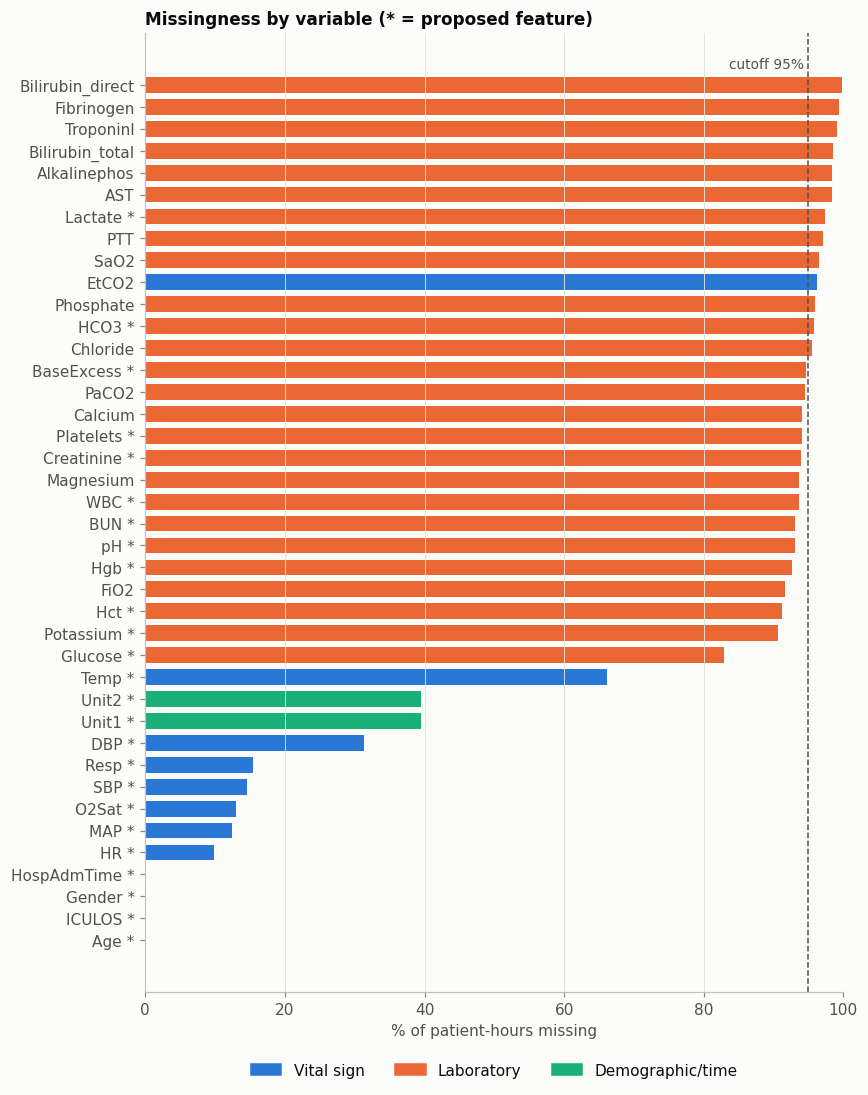

27 variables at or below the cutoff; 13 above: ['Chloride', 'HCO3', 'Phosphate', 'EtCO2', 'SaO2', 'PTT', 'Lactate', 'AST', 'Alkalinephos', 'Bilirubin_total', 'TroponinI', 'Fibrinogen', 'Bilirubin_direct']
Proposed features above the cutoff: ['HCO3', 'Lactate']


In [9]:
fig, ax = plt.subplots(figsize=(8, 10))
labels = [f"{v} *" if p else v for v, p in zip(miss.index, miss["proposed"])]
ax.barh(labels, miss["missing_pct_all"], color=[GROUP_COLORS[g] for g in miss["group"]], height=0.72)
ax.axvline(100 * MISSING_CUTOFF, color=INK2, lw=1, ls="--")
ax.text(100 * MISSING_CUTOFF, len(miss) - 0.4, f"cutoff {MISSING_CUTOFF:.0%} ", color=INK2, ha="right", va="bottom", fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("% of patient-hours missing")
ax.set_title("Missingness by variable (* = proposed feature)")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()], GROUP_COLORS.keys(),
          loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=3)
ax.grid(axis="y", visible=False)
finish(fig, "03_missingness_by_variable")

kept = miss.index[miss["missing_pct_all"] <= 100 * MISSING_CUTOFF].tolist()
flagged = miss.index[miss["missing_pct_all"] > 100 * MISSING_CUTOFF].tolist()
print(f"{len(kept)} variables at or below the cutoff; {len(flagged)} above: {flagged}")
print("Proposed features above the cutoff:", [v for v in flagged if v in PROPOSED] or "none")

We prefer to use the complete variables (Demongraphic and survival data) as predictors.

### 5.1 Set A vs set B

The two hospital systems may record variables differently. Large differences matter for the external validation on set B.

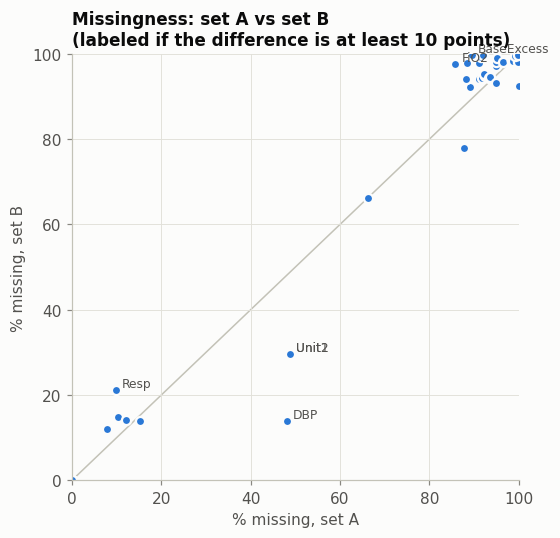

,missing_pct_A,missing_pct_B,A_minus_B
DBP,48.13,13.94,34.18
Unit1,48.87,29.63,19.24
Unit2,48.87,29.63,19.24
FiO2,85.81,97.74,-11.93
Resp,9.78,21.14,-11.36
BaseExcess,89.57,99.77,-10.19
Glucose,87.77,77.84,9.93
pH,88.53,97.77,-9.24
HCO3,91.95,99.81,-7.87
Chloride,91.68,99.38,-7.71


In [10]:
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 100], [0, 100], color=AXIS, lw=1, zorder=1)
ax.scatter(miss["missing_pct_A"], miss["missing_pct_B"], s=36, color=SERIES[0],
           edgecolor=SURFACE, linewidth=1.5, zorder=2)
for v, r in miss.iterrows():
    if abs(r["A_minus_B"]) >= 10:
        ax.annotate(v, (r["missing_pct_A"], r["missing_pct_B"]), xytext=(4, 2),
                    textcoords="offset points", fontsize=8, color=INK2)
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xlabel("% missing, set A"); ax.set_ylabel("% missing, set B")
ax.set_title("Missingness: set A vs set B\n(labeled if the difference is at least 10 points)")
finish(fig, "04_missingness_A_vs_B")
display(miss.loc[miss["A_minus_B"].abs().sort_values(ascending=False).index,
                 ["missing_pct_A", "missing_pct_B", "A_minus_B"]].head(10))

### 5.2 Vital signs over the first 72 hours

Share of patients with a recorded value at each hour since ICU admission.

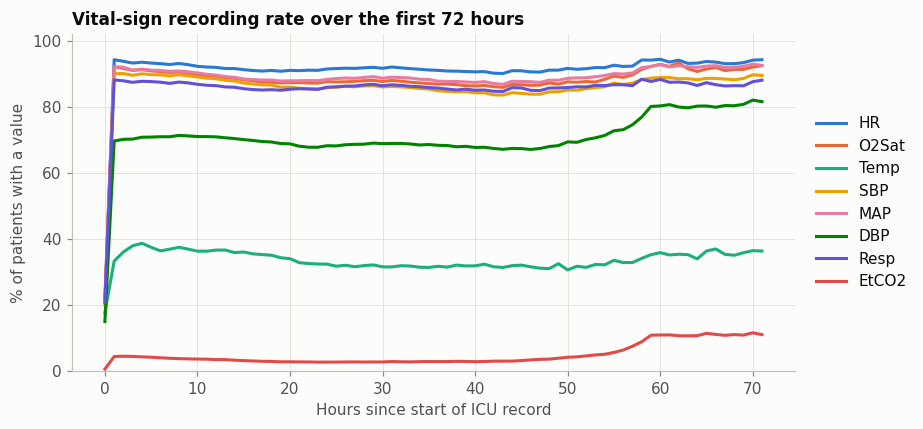

In [11]:
first72 = df[df["hour"] < 72]
rate = first72[VITALS].notna().groupby(first72["hour"]).mean() * 100
fig, ax = plt.subplots(figsize=(8.5, 4))
for i, v in enumerate(VITALS):
    ax.plot(rate.index, rate[v], color=SERIES[i], lw=2, label=v)
ax.set_ylim(0, 102)
ax.set_xlabel("Hours since start of ICU record")
ax.set_ylabel("% of patients with a value")
ax.set_title("Vital-sign recording rate over the first 72 hours")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
finish(fig, "05_vitals_recording_rate")

### 5.3 Which labs are measured together?

Correlation between the "was measured" indicators of the labs. High values reveal panels ordered together (e.g., a blood gas: pH, PaCO2, BaseExcess, HCO3, SaO2).

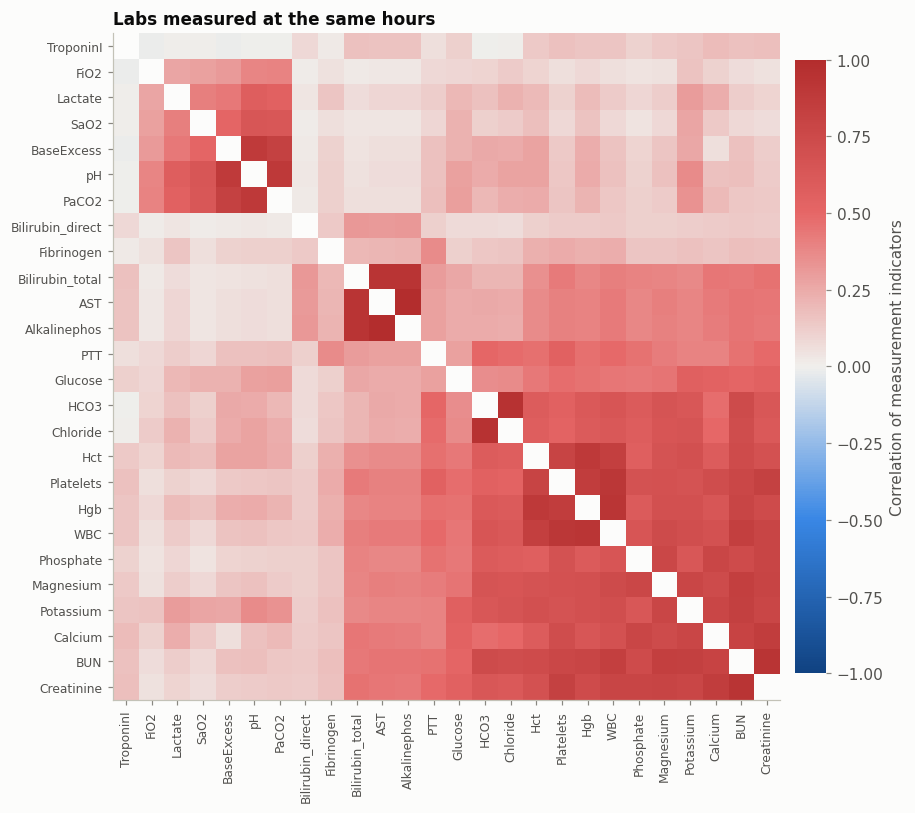

In [12]:
co = obs[LABS].astype(np.float32).corr()
order = list(co.index)
try:
    from scipy.cluster.hierarchy import linkage, leaves_list
    from scipy.spatial.distance import squareform
    dist = squareform((1 - co.fillna(0).to_numpy()).clip(min=0), checks=False)
    order = [co.index[i] for i in leaves_list(linkage(dist, "average"))]
except Exception as e:
    print("scipy not available; labs shown in original order")
co = co.loc[order, order]
mat = co.to_numpy().copy()
np.fill_diagonal(mat, np.nan)   # hide the trivial diagonal so off-diagonal pairs stand out
fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(mat, cmap=BLUE_RED, vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=8)
ax.set_yticks(range(len(order)), order, fontsize=8)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label("Correlation of measurement indicators")
cb.outline.set_visible(False)
ax.set_title("Labs measured at the same hours")
finish(fig, "06_lab_comeasurement")

### 5.4 One example patient

Each cell is one variable in one hour; dark = measured. This is what the RNN will see before forward-filling.

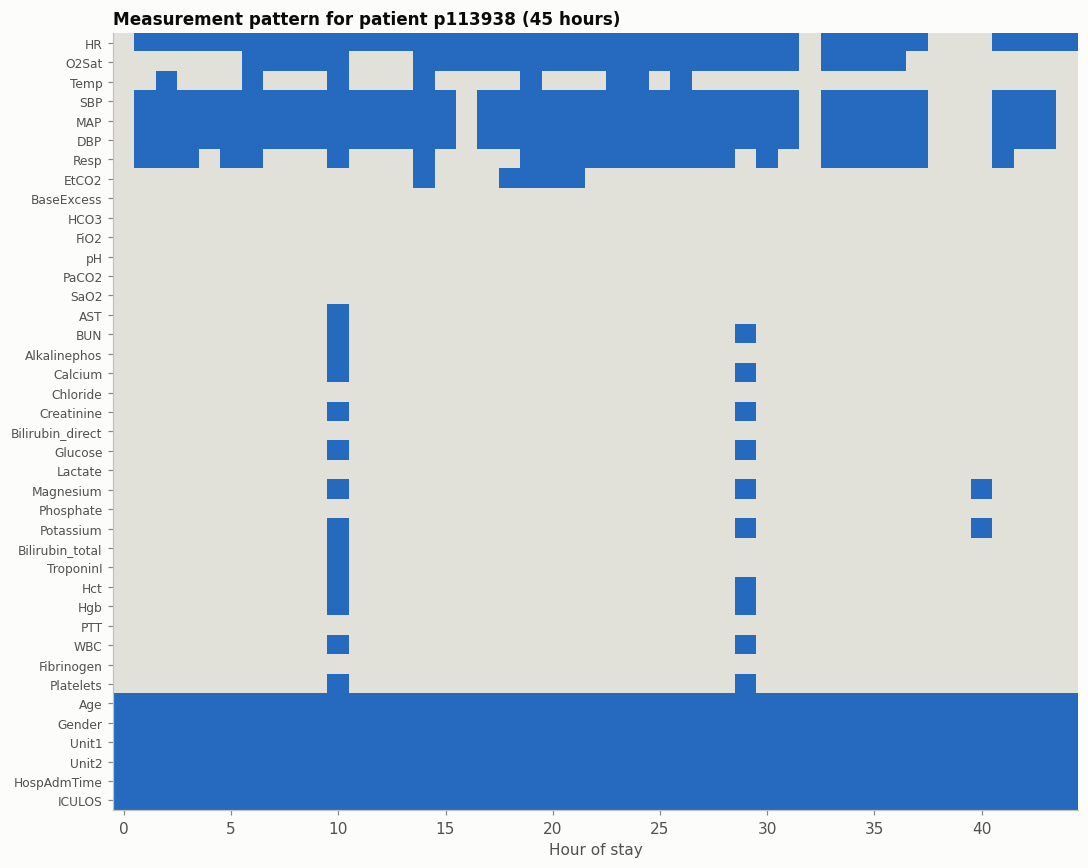

In [13]:
rng = np.random.default_rng(SEED)
candidates = stay.index[(stay["hours"] >= 36) & (stay["hours"] <= 72)]
example = rng.choice(candidates) if len(candidates) else stay.index[0]
one = df[df["patient_id"] == example]
grid = one[FEATURES].notna().T.astype(int)
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(grid.to_numpy(), aspect="auto", cmap=LinearSegmentedColormap.from_list("obs", [GRID, "#256abf"]),
          interpolation="nearest")
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=8)
ax.set_xlabel("Hour of stay")
ax.grid(False)
ax.set_title(f"Measurement pattern for patient {example} ({len(one)} hours)")
finish(fig, "07_example_patient")

## 6. Distributions

Summary statistics, values outside plausible ranges, and skewness (labs with skew > 1 and only positive values are candidates for a log transform).

In [14]:
X = df[FEATURES]
desc = pd.DataFrame({"n_obs": X.notna().sum(), "mean": X.mean(), "sd": X.std(),
                     "min": X.min(), "max": X.max(), "skew": X.skew()})
q = X.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
q.columns = [f"p{int(round(c * 100))}" for c in q.columns]
desc = desc.join(q)
desc["suggest_log"] = (feature_dict.loc[FEATURES, "group"].eq("Laboratory")
                       & (desc["skew"] > 1) & (desc["min"] > 0))
save_table(desc, "08_summary_statistics")
display(desc)
print("Labs suggested for log transform:", desc.index[desc["suggest_log"]].tolist())

,n_obs,mean,sd,min,max,skew,p1,p5,p25,p50,p75,p95,p99,suggest_log
HR,1398811,84.58,17.33,20.00,280.00,0.43,50.00,59.00,72.00,83.50,95.50,115.00,130.00,False
O2Sat,1349474,97.19,2.94,20.00,100.00,-4.15,89.00,92.50,96.00,98.00,99.50,100.00,100.00,False
Temp,525226,36.98,0.77,20.90,50.00,-0.33,35.10,35.80,36.50,37.00,37.50,38.20,38.80,False
SBP,1325945,123.75,23.23,20.00,300.00,0.56,80.00,91.00,107.00,121.00,138.00,165.00,186.00,False
MAP,1358940,82.40,16.34,20.00,300.00,1.05,52.00,60.00,71.00,80.00,92.00,111.00,128.00,False
DBP,1065656,63.83,13.96,20.00,300.00,1.06,38.00,44.00,54.00,62.00,72.00,89.00,103.00,False
Resp,1313875,18.73,5.10,1.00,100.00,0.97,9.00,12.00,15.00,18.00,21.50,28.00,34.00,False
EtCO2,57636,32.96,7.95,10.00,100.00,0.50,13.00,19.00,28.00,33.00,38.00,45.00,52.00,False
BaseExcess,84145,-0.69,4.29,-32.00,100.00,-0.00,-13.00,-7.50,-3.00,0.00,1.00,6.00,11.00,False
HCO3,65028,24.08,4.38,0.00,55.00,0.15,13.00,17.00,22.00,24.00,26.80,31.00,36.00,False


Labs suggested for log transform: ['PaCO2', 'AST', 'BUN', 'Alkalinephos', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'PTT', 'WBC', 'Fibrinogen', 'Platelets']


In [15]:
# Starting ranges for physiologically plausible vital signs; refine with clinical input.
PLAUSIBLE = {"HR": (20, 250), "O2Sat": (50, 100), "Temp": (30, 43), "SBP": (40, 300),
             "MAP": (20, 200), "DBP": (10, 200), "Resp": (4, 70), "EtCO2": (5, 100)}
rows = []
for v, (lo, hi) in PLAUSIBLE.items():
    x = df[v].dropna()
    rows.append({"variable": v, "low": lo, "high": hi, "n_obs": len(x),
                 "below": int((x < lo).sum()), "above": int((x > hi).sum()),
                 "outside_pct": 100 * ((x < lo) | (x > hi)).mean() if len(x) else np.nan})
implausible = save_table(pd.DataFrame(rows).set_index("variable"), "09_implausible_vitals")
display(implausible)

lact = df["Lactate"].dropna()
if len(lact):
    print(f"Lactate median = {lact.median():.2f}. Typical lactate is about 1-2 mmol/L (9-18 mg/dL): "
          f"a median near 1-3 suggests mmol/L, near 10-30 suggests mg/dL.")

,low,high,n_obs,below,above,outside_pct
variable,,,,,,
HR,20,250,1398811,0,4,0.00
O2Sat,50,100,1349474,272,0,0.02
Temp,30,43,525226,16,2,0.00
SBP,40,300,1325945,114,0,0.01
MAP,20,200,1358940,0,444,0.03
DBP,10,200,1065656,0,103,0.01
Resp,4,70,1313875,1787,64,0.14
EtCO2,5,100,57636,0,0,0.00


Lactate median = 1.80. Typical lactate is about 1-2 mmol/L (9-18 mg/dL): a median near 1-3 suggests mmol/L, near 10-30 suggests mg/dL.


### 6.1 Set A vs set B: how big is the batch effect?

Set B is the hospital system kept for external validation, so a shift in the variables we model
matters. One row per patient, each vital summarised as the median over the first `BASE_H = 24`
hours after ICU admission (`ICULOS <= 24`): that compares how sick the patients were on arrival
and is not weighted by how long they stayed. The first observed value is the sensitivity version.

The measure is the **standardized mean difference**, `(mean_A - mean_B) / pooled SD`, with
`|SMD| > 0.1` as the line for "this matters". It is dimensionless, so mmHg, years and percentages
sit in one table, and unlike a p-value it does not grow with the sample size - with about 20,000
patients per set every difference is "significant", so no tests are reported here.

Variables: the four vital values we model (SBP, DBP, HR, Resp) and the three demographics (Age,
sex, and ICULOS as stay length). **MAP is listed separately as the outcome**, since the model
predicts it rather than consumes it.

Patient level, not patient-hour level: hours within a patient are correlated (MAP ICC = 0.55, on
average 34 hours per patient), so hourly rows are not independent observations - the design effect
is roughly 19, and an hour-level comparison would overstate the evidence by that much.

Patients: set A = 20,336, set B = 20,000; with at least one hour in the first 24 h: 40,317


test     n_A     n_B  mean_A  mean_B  mean_diff   smd  smd_lo  smd_hi    q      matters
window                      variable                                                                                                      
first 24 h (primary)        HR             Mann-Whitney   20322   19994   84.24   82.36       1.87  0.12    0.10    0.14 0.00  |SMD| > 0.1
                            SBP            Mann-Whitney   19887   19969  119.05  125.66      -6.61 -0.36   -0.38   -0.34 0.00  |SMD| > 0.1
                            MAP            Mann-Whitney   20319   19871   77.67   85.97      -8.30 -0.66   -0.68   -0.64 0.00  |SMD| > 0.1
                            DBP            Mann-Whitney   12520   19965   59.45   65.93      -6.48 -0.59   -0.61   -0.56 0.00  |SMD| > 0.1
                            Resp           Mann-Whitney   20276   19924   18.10   18.20      -0.10 -0.03   -0.05   -0.01 0.00             
                            Age            Mann-Whitney   20336   20000   62.62   60.65       1.97  0.12    0.10    0.14 0.00  |SMD| > 0.1
                            Gender    chi-square (1 df)   20336   20000    0.58    0.54       0.05  0.09    0.07    0.11 0.00             
first observed value        HR             Mann-Whitney   20335   19996   85.19   84.29       0.90  0.05    0.03    0.07 0.00             
                            SBP            Mann-Whitney   20078   19976  122.04  129.71      -7.67 -0.31   -0.33   -0.29 0.00  |SMD| > 0.1
                            MAP            Mann-Whitney   20334   19898   80.73   89.86      -9.13 -0.53   -0.55   -0.51 0.00  |SMD| > 0.1
                            DBP            Mann-Whitney   12952   19973   62.31   69.31      -7.00 -0.49   -0.51   -0.47 0.00  |SMD| > 0.1
                            Resp           Mann-Whitney   20308   19957   17.40   18.17      -0.77 -0.15   -0.17   -0.13 0.00  |SMD| > 0.1
whole stay                  stay_h         Mann-Whitney   20336   20000   39.77   38.23       1.54  0.07    0.05    0.09 0.00             
all hours (not independent) HR             Mann-Whitney  729026  669785   84.99   84.14       0.84  0.05    0.05    0.05 0.00             
                            SBP            Mann-Whitney  670014  655931  120.96  126.60      -5.64 -0.24   -0.25   -0.24 0.00  |SMD| > 0.1
                            MAP            Mann-Whitney  709357  649583   78.77   86.37      -7.60 -0.48   -0.48   -0.47 0.00  |SMD| > 0.1
                            DBP            Mann-Whitney  409918  655738   59.99   66.23      -6.25 -0.46   -0.46   -0.45 0.00  |SMD| > 0.1
                            Resp           Mann-Whitney  712957  600918   18.77   18.67       0.10  0.02    0.02    0.02 0.00

icu_type,MICU,SICU,unknown
set,,,
A,26.28,26.90,46.82
B,34.62,34.91,30.48


ICU type recorded at all: set A 53.2%, set B 69.5% (chi-square 1,136, p = 2e-247)


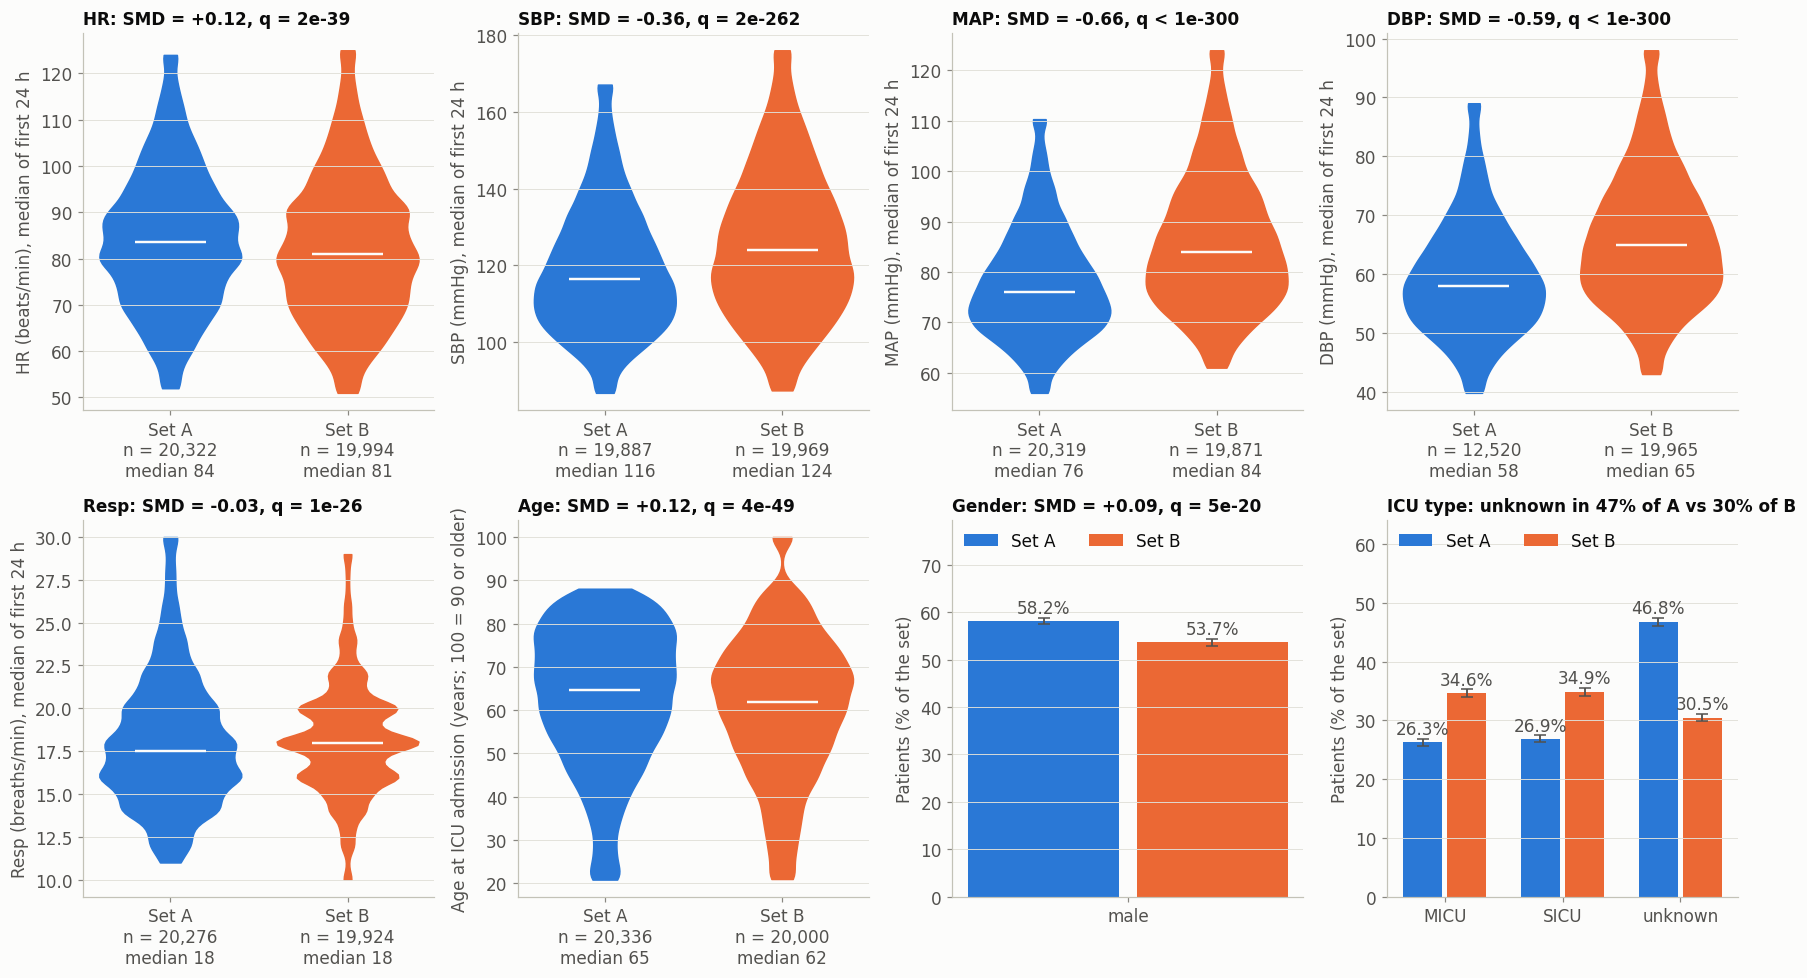

Baseline variables with |SMD| > 0.1: ['HR', 'SBP', 'MAP', 'DBP', 'Age']
Largest shift: MAP (SMD = -0.66)


In [16]:
# How far apart are set A and set B on the variables we model? One row per patient, each vital
# summarised as the median over the first BASE_H hours after ICU admission, so the comparison is
# "how sick on arrival" and is not weighted by stay length. The measure is the standardized mean
# difference (SMD): dimensionless, so mmHg, years and percentages sit in one table, and unlike a
# p-value it does not grow with the sample size. |SMD| > 0.1 is the usual "this matters" line.
from math import sqrt

BASE_H = 24                 # hours after ICU admission that define the baseline window
SMD_CUT = 0.1               # |SMD| above this is a difference that matters
AB_FEATURES = ["SBP", "DBP", "HR", "Resp", "O2Sat"]              # vital values we model
AB_DEMO = ["Age", "Gender", "HospAdmTime", "stay_h"]             # stay_h = last ICULOS
AB_OUTCOME = "MAP"                                  # the forecast target, not an input feature
AB_VITALS = [AB_OUTCOME] + AB_FEATURES
AB_UNITS = {"MAP": "mmHg", "SBP": "mmHg", "DBP": "mmHg", "HR": "beats/min",
            "Resp": "breaths/min", "O2Sat": "%", "Age": "years", "Gender": "fraction male",
            "HospAdmTime": "hours", "stay_h": "hours"}
AB_LABEL = {**{v: f"{v} ({AB_UNITS[v]}), median of first {BASE_H} h" for v in AB_VITALS},
            "Age": "Age at ICU admission (years; 100 = 90 or older)",
            "HospAdmTime": "Hospital admission to ICU (hours; negative = ward stay first)",
            "stay_h": "Stay length (hours, last ICULOS)",
            "Gender": "Male patients (% of the set)"}

# Patient-level table: baseline vitals, demographics, ICU type, stay length.
w24 = df[df["ICULOS"] <= BASE_H]
base = w24.groupby("patient_id").agg({v: "median" for v in AB_VITALS})
first_val = pd.DataFrame({v: df.loc[df[v].notna()].groupby("patient_id")[v].first() for v in AB_VITALS})
static = df.groupby("patient_id").agg(set=("set", "first"), Age=("Age", "first"),
                                      Gender=("Gender", "first"), stay_h=("ICULOS", "max"),
                                      HospAdmTime=("HospAdmTime", "first"),
                                      Unit1=("Unit1", "max"), Unit2=("Unit2", "max"))
static["icu_type"] = np.where(static["Unit1"] == 1, "MICU",
                              np.where(static["Unit2"] == 1, "SICU", "unknown"))
icu_dummies = pd.get_dummies(static["icu_type"], prefix="icu").drop(columns="icu_unknown").astype(float)
base = static.join(base)
first_val = static.join(first_val)
print(f"Patients: set A = {(base['set'] == 'A').sum():,}, set B = {(base['set'] == 'B').sum():,}; "
      f"with at least one hour in the first {BASE_H} h: {base[AB_VITALS].notna().any(axis=1).sum():,}")

def smd_ci(a, b):
    """Standardized mean difference (A - B) with a 95% CI; works for 0/1 variables too."""
    n1, n2 = len(a), len(b)
    v1, v2 = a.var(ddof=1), b.var(ddof=1)
    sp = sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2))
    d = (a.mean() - b.mean()) / sp
    se = sqrt((n1 + n2) / (n1 * n2) + d ** 2 / (2 * (n1 + n2)))
    return d, d - 1.96 * se, d + 1.96 * se

def compare(frame, variables, window):
    out = []
    for v in variables:
        a = frame.loc[frame["set"] == "A", v].dropna().to_numpy(dtype=float)
        b = frame.loc[frame["set"] == "B", v].dropna().to_numpy(dtype=float)
        d, lo, hi = smd_ci(a, b)
        out.append({"window": window, "variable": v,
                    "role": "outcome" if v == AB_OUTCOME else "feature",
                    "n_A": len(a), "n_B": len(b), "mean_A": a.mean(), "mean_B": b.mean(),
                    "sd_A": a.std(ddof=1), "sd_B": b.std(ddof=1), "mean_diff": a.mean() - b.mean(),
                    "pooled_sd": (a.mean() - b.mean()) / d if d else np.nan,
                    "smd": d, "smd_lo": lo, "smd_hi": hi,
                    "median_A": np.median(a), "median_B": np.median(b)})
    return out

ab_rows = compare(base, AB_FEATURES + ["Age", "Gender", "HospAdmTime"], f"first {BASE_H} h (primary)")
ab_rows += compare(base, ["stay_h"], "whole stay")
ab_rows += compare(base, [AB_OUTCOME], f"first {BASE_H} h (primary)")
ab_rows += compare(first_val, AB_FEATURES + [AB_OUTCOME], "first observed value")
ab_tests = pd.DataFrame(ab_rows)
ab_tests["matters"] = np.where(ab_tests["smd"].abs() > SMD_CUT, f"|SMD| > {SMD_CUT}", "")
ab_tests = save_table(ab_tests.set_index(["window", "variable"]), "09a_setAB_smd")
display(ab_tests[["role", "n_A", "n_B", "mean_A", "mean_B", "mean_diff", "pooled_sd",
                  "smd", "smd_lo", "smd_hi", "matters"]])

# ICU type is only documented for part of the patients; kept here because section 6.2 adjusts for it.
icu = save_table(pd.crosstab(base["set"], base["icu_type"], normalize="index").mul(100).round(2),
                 "09b_setAB_icu_type")
display(icu)

pt = ab_tests.loc[f"first {BASE_H} h (primary)"]
panels = [AB_OUTCOME] + AB_FEATURES + ["Age", "HospAdmTime"]
fig, axes = plt.subplots(3, 4, figsize=(16, 13.5))
for ax, v in zip(axes.ravel(), panels):
    r = pt.loc[v] if v != "stay_h" else ab_tests.loc[("whole stay", v)]
    groups, labels = [], []
    for s, n, med in [("A", r["n_A"], r["median_A"]), ("B", r["n_B"], r["median_B"])]:
        x = base.loc[base["set"] == s, v].dropna()
        lo, hi = x.quantile([0.05, 0.95] if v == "HospAdmTime" else [0.01, 0.99])
        groups.append(x.clip(lo, hi).to_numpy())
        labels.append(f"Set {s}\nn = {int(n):,}\nmedian {med:,.0f}")
    parts = ax.violinplot(groups, positions=[1, 2], widths=0.8, showmedians=True, showextrema=False)
    for body, c in zip(parts["bodies"], [SERIES[0], SERIES[1]]):
        body.set_facecolor(c); body.set_edgecolor(c); body.set_alpha(1)
    parts["cmedians"].set_color(SURFACE); parts["cmedians"].set_linewidth(1.6)
    ax.set_xticks([1, 2], labels, fontsize=11)
    ax.set_ylabel(AB_LABEL[v], fontsize=11)
    ax.set_title(f"{v}{' (outcome)' if v == AB_OUTCOME else ''}: SMD = {r['smd']:+.2f} "
                 f"[{r['smd_lo']:+.2f}, {r['smd_hi']:+.2f}]", fontsize=11)
    ax.tick_params(axis="y", labelsize=11)
    ax.grid(axis="x", visible=False)

# Stay length is a count, sex is binary: a violin would misrepresent both.
ax = axes.ravel()[len(panels)]
r = ab_tests.loc[("whole stay", "stay_h")]
bins = np.arange(0, 169, 6)
for s, c in [("A", SERIES[0]), ("B", SERIES[1])]:
    ax.hist(base.loc[base["set"] == s, "stay_h"].clip(upper=168), bins=bins, histtype="step",
            lw=2, color=c, label=f"Set {s} (median {r['median_' + s]:,.0f} h)")
ax.set_xlabel("Stay length (hours; 168+ shown at 168)", fontsize=11)
ax.set_ylabel("Patients", fontsize=11)
ax.set_title(f"ICULOS: SMD = {r['smd']:+.2f} [{r['smd_lo']:+.2f}, {r['smd_hi']:+.2f}]", fontsize=11)
ax.tick_params(labelsize=11)
ax.legend(loc="upper right", fontsize=11, borderaxespad=0.4)

ax = axes.ravel()[len(panels) + 1]
r = pt.loc["Gender"]
top = 0
for k, s in enumerate(["A", "B"]):
    sel = base["set"] == s
    p_hat, n = (base.loc[sel, "Gender"] == 1).mean(), sel.sum()
    err = 1.96 * 100 * sqrt(p_hat * (1 - p_hat) / n)
    ax.bar(k, 100 * p_hat, width=0.6, color=SERIES[k], yerr=err, capsize=4, ecolor=INK2,
           error_kw={"lw": 1.2})
    ax.annotate(f"{100 * p_hat:.1f}%", (k, 100 * p_hat + err), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=11, color=INK2)
    top = max(top, 100 * p_hat + err)
ax.set_xticks([0, 1], [f"Set {s}\nn = {int(n):,}" for s, n in
                       [("A", r["n_A"]), ("B", r["n_B"])]], fontsize=11)
ax.set_ylim(0, top * 1.3)
ax.set_ylabel(AB_LABEL["Gender"], fontsize=11)
ax.set_title(f"Gender: SMD = {r['smd']:+.2f} [{r['smd_lo']:+.2f}, {r['smd_hi']:+.2f}]", fontsize=11)
ax.tick_params(axis="y", labelsize=11)
ax.grid(axis="x", visible=False)
for ax in axes.ravel()[len(panels) + 2:]:
    ax.axis("off")
finish(fig, "09c_setAB_violins")

feat = pt[pt["role"] == "feature"]
big = feat.index[feat["smd"].abs() > SMD_CUT].tolist()
print(f"Features above |SMD| {SMD_CUT}: {big or 'none'}  (mean |SMD| over the features "
      f"{feat['smd'].abs().mean():.2f})")
print(f"Outcome {AB_OUTCOME}: SMD {pt.loc[AB_OUTCOME, 'smd']:+.2f} - the batch effect sits in the "
      "variable we are trying to predict, which is why it cannot simply be corrected away.")

### 6.2 Is the gap just a different case mix?

Each baseline variable is regressed on the set indicator plus age, sex and ICU type. If the hospital
difference is really "set A admits older, sicker patients", the set coefficient shrinks after
adjustment; whatever is left is a hospital effect (different population, different devices, or a
different measurement protocol). `pct_explained_by_case_mix` is how much of the crude gap the
covariates absorb - a negative value means adjustment makes the gap slightly wider.

,n,crude_diff,adj_diff,crude_smd,adj_smd,adj_p,pct_explained_by_case_mix
variable,,,,,,,
HR,40316,1.87,3.06,0.12,0.20,0.00,-63.22
SBP,39856,-6.61,-7.44,-0.36,-0.40,0.00,-12.44
MAP,40190,-8.30,-8.65,-0.66,-0.69,0.00,-4.26
DBP,32485,-6.48,-5.65,-0.59,-0.51,0.00,12.82
Resp,40200,-0.10,-0.01,-0.03,-0.00,0.82,91.39
Age,40336,1.97,2.33,0.12,0.14,0.00,-18.18


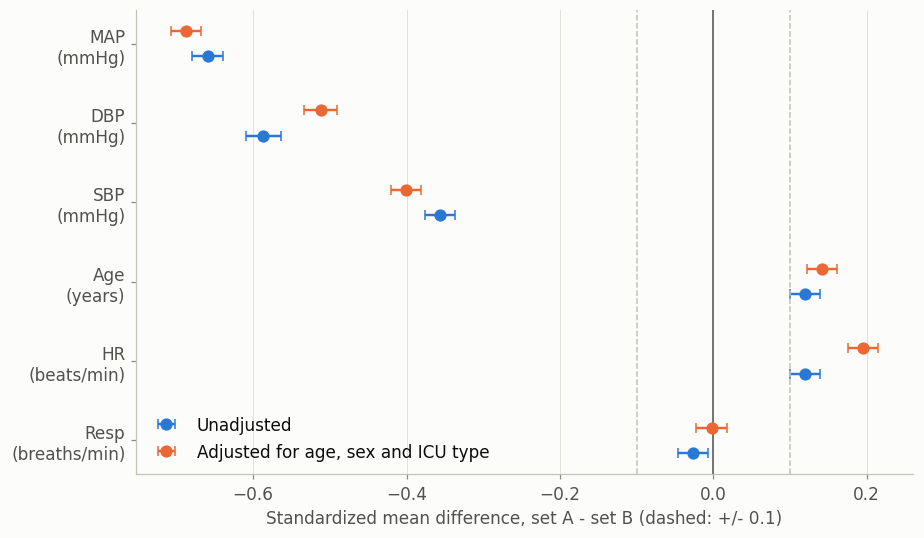

After adjustment the largest remaining gap is MAP: SMD -0.69 (unadjusted -0.66); age, sex and ICU type explain -4% of that gap.
Variables still above |SMD| 0.1 after adjustment: ['HR', 'SBP', 'MAP', 'DBP', 'Age']


In [17]:
# Is the hospital gap just a different case mix? Each baseline variable is regressed on the
# set indicator plus age, sex and ICU type (ICU type kept as a three-level factor so the
# patients with no unit recorded are not dropped). The adjusted difference is what is left
# of the A - B gap once those patient-mix differences are held fixed.
import statsmodels.api as sm

ADJ_COVS = ["Age", "Gender", "icu_type"]

def design(frame, covs, intercept=True):
    X = pd.DataFrame({"set_B": (frame["set"] == "B").astype(float)}, index=frame.index)
    for c in covs:
        if c == "icu_type":
            X = X.join(icu_dummies.loc[frame.index])
        else:
            X[c] = frame[c].astype(float)
    return sm.add_constant(X) if intercept else X

adj_rows = []
for v in AB_VITALS + ["Age"]:
    covs = [c for c in ADJ_COVS if c != v]
    d = base.loc[base[v].notna()]
    y = d[v].astype(float)
    a, b = y[d["set"] == "A"], y[d["set"] == "B"]
    sp = sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    crude = sm.OLS(y, design(d, [])).fit()
    adj = sm.OLS(y, design(d, covs)).fit()
    adj_rows.append({"variable": v, "n": len(d), "covariates": "+".join(covs),
                     "crude_diff": -crude.params["set_B"], "crude_smd": -crude.params["set_B"] / sp,
                     "adj_diff": -adj.params["set_B"], "adj_se": adj.bse["set_B"],
                     "adj_smd": -adj.params["set_B"] / sp, "adj_smd_se": adj.bse["set_B"] / sp,
                     "adj_p": adj.pvalues["set_B"],
                     "pct_explained_by_case_mix": 100 * (1 - adj.params["set_B"] / crude.params["set_B"]),
                     "r2_covariates_only": sm.OLS(y, design(d, covs, True).drop(columns="set_B")).fit().rsquared})
adjusted = save_table(pd.DataFrame(adj_rows).set_index("variable"), "09d_setAB_adjusted")
display(adjusted[["n", "crude_diff", "adj_diff", "crude_smd", "adj_smd", "adj_p",
                  "pct_explained_by_case_mix"]])

order = adjusted["crude_smd"].abs().sort_values().index
fig, ax = plt.subplots(figsize=(8.5, 5))
yy = np.arange(len(order))
for off, col, key, se_key, lab in [(-0.16, SERIES[0], "crude_smd", None, "Unadjusted"),
                                   (0.16, SERIES[1], "adj_smd", "adj_smd_se",
                                    "Adjusted for age, sex and ICU type")]:
    val = adjusted.loc[order, key].to_numpy()
    err = 1.96 * adjusted.loc[order, se_key].to_numpy() if se_key else np.full(len(order), np.nan)
    if se_key is None:
        n1 = ab_tests.loc[(f"first {BASE_H} h (primary)", list(order)), "n_A"].to_numpy()
        n2 = ab_tests.loc[(f"first {BASE_H} h (primary)", list(order)), "n_B"].to_numpy()
        err = 1.96 * np.sqrt((n1 + n2) / (n1 * n2) + val ** 2 / (2 * (n1 + n2)))
    ax.errorbar(val, yy + off, xerr=err, fmt="o", ms=7, color=col, ecolor=col,
                elinewidth=1.6, capsize=3, label=lab)
ax.axvline(0, color=INK2, lw=1)
for t in (-SMD_CUT, SMD_CUT):
    ax.axvline(t, color=AXIS, lw=1, ls="--")
ax.set_yticks(yy, [f"{v}\n({AB_UNITS[v]})" for v in order], fontsize=11)
ax.set_xlabel(f"Standardized mean difference, set A - set B (dashed: +/- {SMD_CUT})", fontsize=11)
ax.tick_params(axis="x", labelsize=11)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", fontsize=11, borderaxespad=0.4)
finish(fig, "09d_setAB_smd_forest")

worst = adjusted["adj_smd"].abs().idxmax()
print(f"After adjustment the largest remaining gap is {worst}: SMD {adjusted.loc[worst, 'adj_smd']:+.2f} "
      f"(unadjusted {adjusted.loc[worst, 'crude_smd']:+.2f}); age, sex and ICU type explain "
      f"{adjusted.loc[worst, 'pct_explained_by_case_mix']:.0f}% of that gap.")
print(f"Variables still above |SMD| {SMD_CUT} after adjustment: "
      f"{adjusted.index[adjusted['adj_smd'].abs() > SMD_CUT].tolist() or 'none'}")

### 6.3 Training strategy: how separable are the two hospitals?

A domain classifier predicts the set from the baseline record. AUROC near 0.5 means A and B look
like one population (pool them and keep B as a clean test set); the higher it goes, the more a model
trained on A extrapolates when applied to B. Two feature sets are compared on purpose: *values only*
(the patient's state) and *values + recording* (which variables were measured at all), because the
second one is the hospital's documentation practice rather than the patient. The gap between the two
AUROCs says how much of the shift our model would be learning from measurement habits.

The other half of the decision - how much performance actually drops from A to B - can only be
measured once the MAP model exists; the recipe is printed at the end of the cell.

Both model classes are run on both feature sets on purpose. A boosted model that beats the logistic one by a wide margin on the *same* columns is not finding more physiology - it is finding structure a linear model cannot use, which for site data usually means number formatting. The check at the end of the cell tests exactly that.

,n_features,auroc,auroc_fold_mean,auroc_fold_sd
model,,,,
values only (logistic),7,0.70,0.70,0.00
values only (gradient boosting),7,0.95,0.95,0.00
values + recording (logistic),15,0.86,0.86,0.00
values + recording (gradient boosting),15,0.97,0.97,0.00


,coef_toward_B
DBP_measured,3.80
MAP,1.34
MAP_measured,-0.47
icu_MICU,0.42
icu_recorded,0.40
SBP,-0.35
SBP_measured,-0.35
HR,-0.34


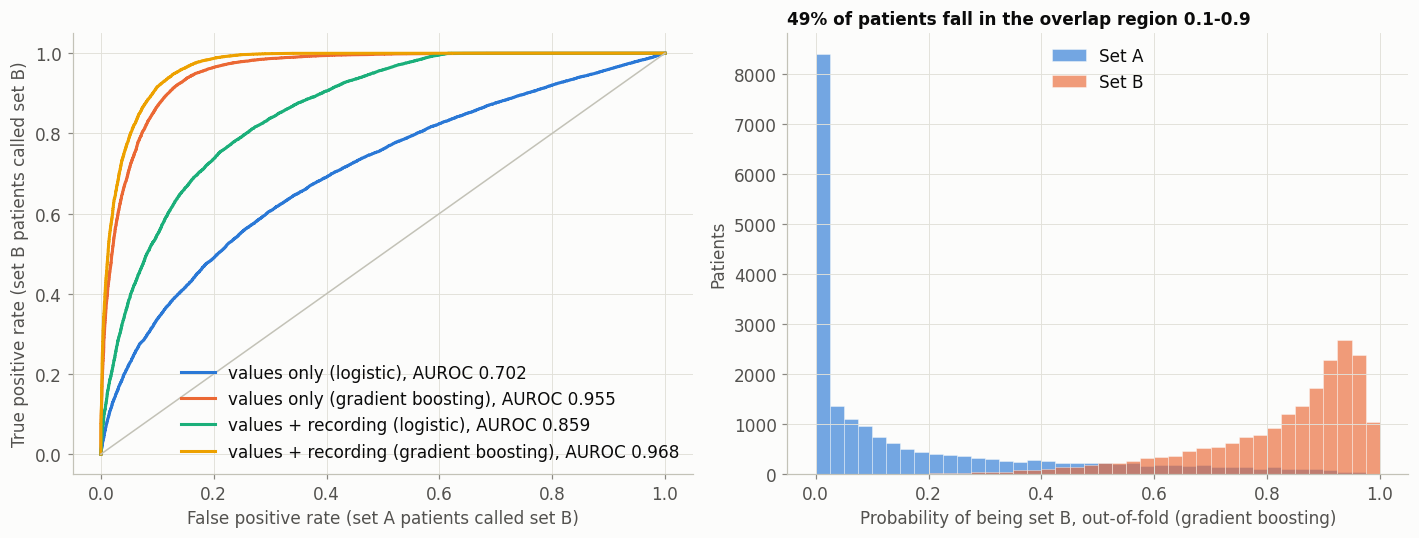

Domain AUROC = 0.968 -> strong shift: expect a real drop on set B. Train on A, validate on B, and compare against (i) adding site as a covariate, (ii) importance weighting by the domain score, and (iii) fine-tuning or refitting on a slice of B.
Within the logistic models: values only 0.702 -> values + recording 0.859; that gap is documentation practice rather than patient state. Boosting reaches 0.955 on the same seven values, which is not extra physiology - see the formatting check below.
Overlap region (domain score 0.1-0.9) holds 49% of patients; importance weighting is only trustworthy where the two sets overlap.

Still to measure once the MAP model exists: the A -> B external-validation drop. Fit on set A, report the same metric (RMSE / AUPRC for MAP < 65) under 5-fold CV within A and on all of set B; the difference is the cost of the shift. Refitting the model inside B separates 'B is shifted' from 'B is simply harder to predict'.


,pct_whole_number_A,n_distinct_A,pct_whole_number_B,n_distinct_B
variable,,,,
Age,1.05,5971,100.00,77
HR,95.05,333,93.06,311
SBP,91.38,762,94.12,792
MAP,77.49,915,94.45,418
DBP,91.97,398,94.16,609
Resp,92.83,199,95.00,151
Temp,7.64,597,11.58,209


Age is,has decimals,whole number
set,,
A,20123,213
B,0,20000


Age alone identifies the hospital for 99.5% of patients: set A stores a fractional age (5,971 distinct values), set B rounds to whole years (77 distinct values). MAP is on a different grid too: whole numbers in 77% of set A hours vs 94% of set B hours.
That is a formatting fingerprint, not physiology: a tree can isolate the integers, a linear model cannot. Any flexible model (boosting, an RNN) trained on A and B pooled can therefore recover the site from the decimals and behave differently per site, which inflates a pooled evaluation. Section 6.4 puts both hospitals on one value grid and measures how much of the 0.955 was formatting, how much was missingness, and how much is a real patient-state shift.


In [18]:
# Training strategy: a domain classifier asks how separable the two hospitals are from the
# baseline record alone. AUROC near 0.5 means A and B look like the same population (pool
# them); the higher it goes, the more a model trained on A is extrapolating on B.
# "values only" uses the patient's state; "+ recording" adds which variables were measured
# at all, which is the hospital's documentation practice rather than the patient.
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_val = base[AB_VITALS + ["Age", "Gender"]].astype(float)
X_rec = X_val.join(base[AB_VITALS].notna().astype(float).add_suffix("_measured")) \
             .join(icu_dummies).assign(icu_recorded=(base["icu_type"] != "unknown").astype(float))
y_dom = (base["set"] == "B").astype(int).to_numpy()
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

def logistic():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(max_iter=2000))

def boosted():   # imputed like the logistic models, so a NaN cannot itself mark the site
    return make_pipeline(SimpleImputer(strategy="median"),
                         HistGradientBoostingClassifier(random_state=SEED))

DOMAIN_MODELS = {
    "values only (logistic)": (X_val, logistic),
    "values only (gradient boosting)": (X_val, boosted),
    "values + recording (logistic)": (X_rec, logistic),
    "values + recording (gradient boosting)": (X_rec, boosted),
}

dom_rows, dom_scores = [], {}
for name, (X, make) in DOMAIN_MODELS.items():
    Xa, folds, oof = X.to_numpy(dtype=float), [], np.zeros(len(y_dom))
    for tr, te in cv.split(Xa, y_dom):
        m = make().fit(Xa[tr], y_dom[tr])
        oof[te] = m.predict_proba(Xa[te])[:, 1]
        folds.append(roc_auc_score(y_dom[te], oof[te]))
    dom_scores[name] = oof
    dom_rows.append({"model": name, "n_features": X.shape[1], "auroc": roc_auc_score(y_dom, oof),
                     "auroc_fold_mean": np.mean(folds), "auroc_fold_sd": np.std(folds, ddof=1)})
domain = save_table(pd.DataFrame(dom_rows).set_index("model"), "09e_domain_classifier")
display(domain)

# Which baseline features separate the hospitals? Standardized logistic coefficients.
lg = logistic().fit(X_rec.to_numpy(dtype=float), y_dom)
coef = pd.Series(lg[-1].coef_[0], index=X_rec.columns, name="coef_toward_B")
coef = save_table(coef.reindex(coef.abs().sort_values(ascending=False).index).to_frame(),
                  "09f_domain_coefficients")
display(coef.head(8))

main = "values + recording (gradient boosting)"
score = dom_scores[main]
overlap = ((score > 0.1) & (score < 0.9)).mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
for i, (name, s) in enumerate(dom_scores.items()):
    fpr, tpr, _ = roc_curve(y_dom, s)
    ax.plot(fpr, tpr, color=SERIES[i], lw=2,
            label=f"{name}, AUROC {roc_auc_score(y_dom, s):.3f}")
ax.plot([0, 1], [0, 1], color=AXIS, lw=1)
ax.set_xlabel("False positive rate (set A patients called set B)", fontsize=11)
ax.set_ylabel("True positive rate (set B patients called set B)", fontsize=11)
ax.tick_params(labelsize=11)
ax.legend(loc="lower right", fontsize=11, borderaxespad=0.4)

ax = axes[1]
bins = np.linspace(0, 1, 41)
for s, c in [("A", SERIES[0]), ("B", SERIES[1])]:
    ax.hist(score[(base["set"] == s).to_numpy()], bins=bins, color=c, alpha=0.65,
            edgecolor=SURFACE, linewidth=0.4, label=f"Set {s}")
ax.set_xlabel("Probability of being set B, out-of-fold (gradient boosting)", fontsize=11)
ax.set_ylabel("Patients", fontsize=11)
ax.tick_params(labelsize=11)
ax.legend(loc="upper center", fontsize=11, borderaxespad=0.4)
ax.set_title(f"{100 * overlap:.0f}% of patients fall in the overlap region 0.1-0.9", fontsize=11)
finish(fig, "09e_domain_classifier")

auc = domain.loc[main, "auroc"]
advice = ("A and B are nearly exchangeable: pool them and keep set B purely as a held-out test"
          if auc < 0.6 else
          "moderate shift: pool, but add the site as a covariate / random effect and report set B separately"
          if auc < 0.75 else
          "strong shift: expect a real drop on set B. Train on A, validate on B, and compare against "
          "(i) adding site as a covariate, (ii) importance weighting by the domain score, and "
          "(iii) fine-tuning or refitting on a slice of B")
print(f"Domain AUROC = {auc:.3f} -> {advice}.")
print(f"Within the logistic models: values only {domain.loc['values only (logistic)', 'auroc']:.3f} -> "
      f"values + recording {domain.loc['values + recording (logistic)', 'auroc']:.3f}; that gap is "
      "documentation practice rather than patient state. Boosting reaches "
      f"{domain.loc['values only (gradient boosting)', 'auroc']:.3f} on the same seven values, which is "
      "not extra physiology - see the formatting check below.")
print(f"Overlap region (domain score 0.1-0.9) holds {100 * overlap:.0f}% of patients; "
      "importance weighting is only trustworthy where the two sets overlap.")
print("\nStill to measure once the MAP model exists: the A -> B external-validation drop. "
      "Fit on set A, report the same metric (RMSE / AUPRC for MAP < 65) under 5-fold CV within A "
      "and on all of set B; the difference is the cost of the shift. Refitting the model inside B "
      "separates 'B is shifted' from 'B is simply harder to predict'.")

# Boosting beats logistic by a wide margin on the same columns, which is a warning sign: trees can
# isolate narrow value ranges, so they pick up how each hospital *formats* its numbers.
fing_rows = []
for v in ["Age"] + AB_VITALS + ["Temp"]:
    x = base[["set", "Age"]].dropna() if v == "Age" else df[["set", v]].dropna()
    r = {"variable": v}
    for st in ["A", "B"]:
        col = x.loc[x["set"] == st, v].astype(float)
        r[f"pct_whole_number_{st}"] = 100 * np.isclose(col % 1, 0).mean()
        r[f"n_distinct_{st}"] = col.round(3).nunique()
    fing_rows.append(r)
fingerprint = save_table(pd.DataFrame(fing_rows).set_index("variable"), "09g_site_fingerprint")
display(fingerprint)

whole_age = np.isclose(base["Age"].astype(float) % 1, 0)
display(pd.crosstab(base["set"], pd.Series(np.where(whole_age, "whole number", "has decimals"),
                                           index=base.index, name="Age is")))
acc = max((whole_age == (base["set"] == "B")).mean(), (whole_age == (base["set"] == "A")).mean())
print(f"Age alone identifies the hospital for {100 * acc:.1f}% of patients: set A stores a fractional "
      f"age ({base.loc[base['set'] == 'A', 'Age'].round(3).nunique():,} distinct values), set B rounds "
      f"to whole years ({base.loc[base['set'] == 'B', 'Age'].round(3).nunique()} distinct values). "
      f"MAP is on a different grid too: whole numbers in {fingerprint.loc['MAP', 'pct_whole_number_A']:.0f}% "
      f"of set A hours vs {fingerprint.loc['MAP', 'pct_whole_number_B']:.0f}% of set B hours.")
print("That is a formatting fingerprint, not physiology: a tree can isolate the integers, a linear "
      "model cannot. Any flexible model (boosting, an RNN) trained on A and B pooled can therefore "
      "recover the site from the decimals and behave differently per site, which inflates a pooled "
      "evaluation. Section 6.4 puts both hospitals on one value grid and measures how much of the "
      "0.955 was formatting, how much was missingness, and how much is a real patient-state shift.")

### 6.4 Removing the site fingerprint before any pooled training

Section 6.3 leaves a question open: a boosted model scores 0.955 on the same seven values where a
logistic model scores 0.702. Putting both hospitals on one value grid and then re-running the
classifier splits that gap into its parts, and only the last part belongs in the report:

- **formatting** (fractional age, MAP recorded in thirds) - disappears once the grids match
- **missingness leaking through imputation** - median imputation puts 38% of set A patients at the
  exact same DBP, which a tree reads as a site label even though no mask was handed to it. This is
  the part to watch in the model: it arrives without anyone choosing to add a mask feature
- **genuine patient-state shift** - what `values only (logistic) = 0.70` was measuring all along

**Only the variables we model are touched**: MAP, SBP, DBP, HR, Resp (rounded to whole units) and
Age. ICULOS and sex already share a grid - whole hours and 0/1 in both sets - so they need
nothing. Temp, O2Sat, EtCO2 and the labs keep their full precision; they carry fingerprints of
their own (BaseExcess is 98% whole numbers in set A against 8% in set B), so adding any of them
to the feature set later means harmonizing them first.

**Age is handled by exclusion, not by clipping.** Set A holds nobody outside [18.11, 89.00], and
that ceiling is not top-coding: there is no pile-up at 89, the distribution simply stops, so the
90+ patients are absent from set A's cohort altogether. Set B instead keeps them under the code
100 (392 patients, with nobody at all between 90 and 99) and includes 22 minors. Folding those
onto 89 would heap 2.5% of set B on a single year that set A barely occupies - a new, smaller
fingerprint - so set B is cut to set A's range instead: **414 patients dropped**, leaving
20,336 set A and 19,586 set B. `09i_age_alignment.png` shows both distributions before and after.

The harmonized table is cached as `physionet2019_harmonized.pkl` for the modelling stage. Note
what none of this does: it removes the fingerprint, not the shift. MAP is still 8 mmHg lower in
set A afterwards, because that difference is in the values themselves.

In [19]:
# Put the variables we model on one value grid in both hospitals, so that no model can read the
# site off the number formatting, and cut both hospitals to the same age range. Only the variables
# the model actually uses are touched; the grids come from the raw data (09g):
#   MAP, SBP, DBP, HR, Resp, O2Sat   both sets use a .0/.5 grid, but set A also records MAP in
#           thirds (.33 or .67 in 17% of its hours) and some quarters -> round to whole units,
#           which moves a value by at most 0.5.
#   HospAdmTime   set A's fractional parts pile up on .97-.99 while set B's pile up on .00, and
#           that fractional part alone tells the hospitals apart at AUROC 0.71 -> round to whole
#           hours. Rounding does not finish the job: the rounded variable still separates the
#           sites at 0.72, because the distributions genuinely differ (median -3 h in set A
#           against -9 h in set B, and set B never records a positive value). See the site AUROC
#           column in model/batch_effect.py.
#   Age     set A holds nobody outside [18.11, 89.00], and its ceiling is not top-coding: there is
#           no pile-up at 89, the distribution simply stops, so set A's cohort is missing the 90+
#           patients altogether. Set B instead codes 90+ as 100 (392 patients) and includes 22
#           minors. Folding those onto 89 would heap 2.5% of set B on a year set A barely
#           occupies, so set B is cut to set A's range: round to whole years, then drop the 414
#           patients outside [18, 89].
#   ICULOS, Gender   already on identical grids (100% whole numbers, 0/1) - nothing to do.
# Variables outside the model (Temp, O2Sat, EtCO2, BaseExcess, PaCO2) keep their full precision.
# They carry fingerprints of their own - BaseExcess is 98% whole numbers in set A against 8% in
# set B - so anything that adds them to the feature set has to harmonize them first.
VALUE_GRID = {**{v: 1.0 for v in AB_VITALS}, "HospAdmTime": 1.0}
AGE_RANGE = (18, 89)
HARM_CACHE = DATA_DIR / "physionet2019_harmonized.pkl"

def harmonize_site_grid(frame):
    """Round the modelled variables onto a shared grid and cut both sets to the same age range.
    Age is constant within a patient, so the row filter drops whole patients."""
    out = frame.copy()
    out["Age"] = out["Age"].round(0)
    for v, step in VALUE_GRID.items():
        out[v] = ((out[v] / step).round() * step).astype("float32")
    return out[out["Age"].between(*AGE_RANGE)].reset_index(drop=True)

df_h = harmonize_site_grid(df)
df_h.to_pickle(HARM_CACHE)
age0 = df.groupby("patient_id").agg(set=("set", "first"), Age=("Age", "first"))
dropped = age0[~age0["Age"].between(*AGE_RANGE)]
print(f"Harmonized table written to {HARM_CACHE}\n  {len(df_h):,} rows, "
      f"{df_h['patient_id'].nunique():,} patients "
      f"({df_h.groupby('set')['patient_id'].nunique().to_dict()})")
print(f"  excluded to match the age ranges: {len(dropped):,} patients, all from set "
      f"{'/'.join(sorted(dropped['set'].unique()))} - {int((dropped['Age'] > 89).sum())} coded 90+ "
      f"and {int((dropped['Age'] < 18).sum())} under 18")
kept_rows = df["Age"].round(0).between(*AGE_RANGE).to_numpy()
print("  largest value change:",
      {v: round(float(np.nanmax(np.abs(df.loc[kept_rows, v].to_numpy() - df_h[v].to_numpy()))), 2)
       for v in VALUE_GRID})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
bins = np.arange(13.5, 101.5, 1)
for ax, (frame, title) in zip(axes, [
        (df.groupby("patient_id").agg(set=("set", "first"), Age=("Age", "first")),
         f"Before: set B heaps {int((age0['Age'] >= 100).sum())} patients on the 90+ code 100"),
        (df_h.groupby("patient_id").agg(set=("set", "first"), Age=("Age", "first")),
         f"After: both sets on whole years in [{AGE_RANGE[0]}, {AGE_RANGE[1]}]")]):
    for s, c in [("A", SERIES[0]), ("B", SERIES[1])]:
        x = frame.loc[frame["set"] == s, "Age"]
        ax.hist(x, bins=bins, histtype="step", lw=1.8, color=c,
                label=f"Set {s} (n = {len(x):,}, median {x.median():.0f})")
    ax.set_xlabel("Age at ICU admission (years)", fontsize=11)
    ax.set_title(title, fontsize=11)
    ax.tick_params(labelsize=11)
    ax.legend(loc="upper left", fontsize=11, borderaxespad=0.4)
axes[0].set_ylabel("Patients", fontsize=11)
finish(fig, "09i_age_alignment")

# Does the grid work? Re-run the domain classifier on raw and harmonized data. Two feature sets
# are used on purpose: all values with median imputation, and the near-complete ones on complete
# cases only - median imputation puts 38% of set A patients at the exact same DBP, which a tree
# reads as a site label even though no mask was given to it.
NO_DBP = ["HR", "SBP", "MAP", "Resp", "O2Sat", "Age", "Gender"]

def domain_auroc(frame, columns, complete_only):
    """5-fold out-of-fold AUROC for telling the two hospitals apart from the baseline record."""
    w = frame[frame["ICULOS"] <= BASE_H]
    b = frame.groupby("patient_id").agg(set=("set", "first"), Age=("Age", "first"),
                                        Gender=("Gender", "first")).join(w.groupby("patient_id")[AB_VITALS].median())
    X = b[columns].astype(float)
    keep = X.notna().all(axis=1).to_numpy() if complete_only else np.ones(len(X), bool)
    X, yy = X[keep], (b["set"] == "B").astype(int).to_numpy()[keep]
    out = {}
    for mname, make in [("logistic", logistic), ("gradient boosting", boosted)]:
        oof, Xa = np.zeros(len(yy)), X.to_numpy(float)
        for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xa, yy):
            oof[te] = make().fit(Xa[tr], yy[tr]).predict_proba(Xa[te])[:, 1]
        out[mname] = roc_auc_score(yy, oof)
    return {"n": len(yy), **out}

harm_rows = []
for data_label, frame in [("raw", df), ("harmonized", df_h)]:
    for feat_label, cols, comp in [("all vitals + age + sex, imputed", AB_VITALS + ["Age", "Gender"], False),
                                   ("near-complete only, complete cases", NO_DBP, True)]:
        harm_rows.append({"data": data_label, "features": feat_label, **domain_auroc(frame, cols, comp)})
harm = save_table(pd.DataFrame(harm_rows).set_index(["data", "features"]), "09h_harmonization_check")
display(harm)

raw_gbm = harm.loc[("raw", "all vitals + age + sex, imputed"), "gradient boosting"]
h_gbm = harm.loc[("harmonized", "all vitals + age + sex, imputed"), "gradient boosting"]
h_clean = harm.loc[("harmonized", "near-complete only, complete cases"), "gradient boosting"]
h_lin = harm.loc[("harmonized", "near-complete only, complete cases"), "logistic"]
print(f"\nBoosted domain AUROC {raw_gbm:.3f} (raw) -> {h_gbm:.3f} (grid and age range aligned) -> "
      f"{h_clean:.3f} (also dropping the imputed DBP column), against {h_lin:.3f} for the linear "
      "model on the same columns. So the separability splits roughly into three parts:")
print(f"  {raw_gbm - h_gbm:+.2f}  number formatting (fractional age, MAP recorded in thirds)")
print(f"  {h_gbm - h_clean:+.2f}  missingness leaking in through median imputation, not through a mask")
print(f"  {h_clean - h_lin:+.2f}  real non-linear structure a logistic model cannot use")
print(f"  {h_lin:.2f}   the genuine patient-state shift, which is what the report should quote")
print("\nFor the modelling stage: load physionet2019_harmonized.pkl, impute with an explicit mask "
      "column rather than letting a constant stand in silently, and keep A -> B as the test split.")

Harmonized table written to /scratch/kinfai_root/kinfai0/mhanyu/biostats664/final_proj/datasets/physionet2019_harmonized.pkl (1,552,210 rows). Patients affected by the age rule:
age 90+ recoded to 89 (set B only)     392
age < 18 clipped to 18 (set B only)     22
Largest value change per variable (mmHg / C / units): {'MAP': 0.5, 'SBP': 0.5, 'HR': 0.5, 'Temp': 0.25, 'BaseExcess': 0.5}


n  logistic  gradient boosting
data       features                                                           
raw        all 7, median-imputed            40336      0.70               0.95
           6 near-complete, complete cases  39635      0.70               0.94
harmonized all 7, median-imputed            40336      0.70               0.85
           6 near-complete, complete cases  39635      0.70               0.76


Boosted domain AUROC 0.955 (raw) -> 0.851 (grids harmonized) -> 0.756 (also dropping the imputed DBP column), against 0.703 for the linear model on the same columns. So the separability splits roughly into three parts:
  +0.10  number formatting (fractional age, MAP recorded in thirds)
  +0.10  missingness leaking in through median imputation, not through a mask
  +0.05  real non-linear structure a logistic model cannot use
  0.70   the genuine patient-state shift, which is what the report should quote

For the modelling stage: load physionet2019_harmonized.pkl, impute with an explicit mask column rather than letting a constant stand in silently, and keep A -> B as the test split.


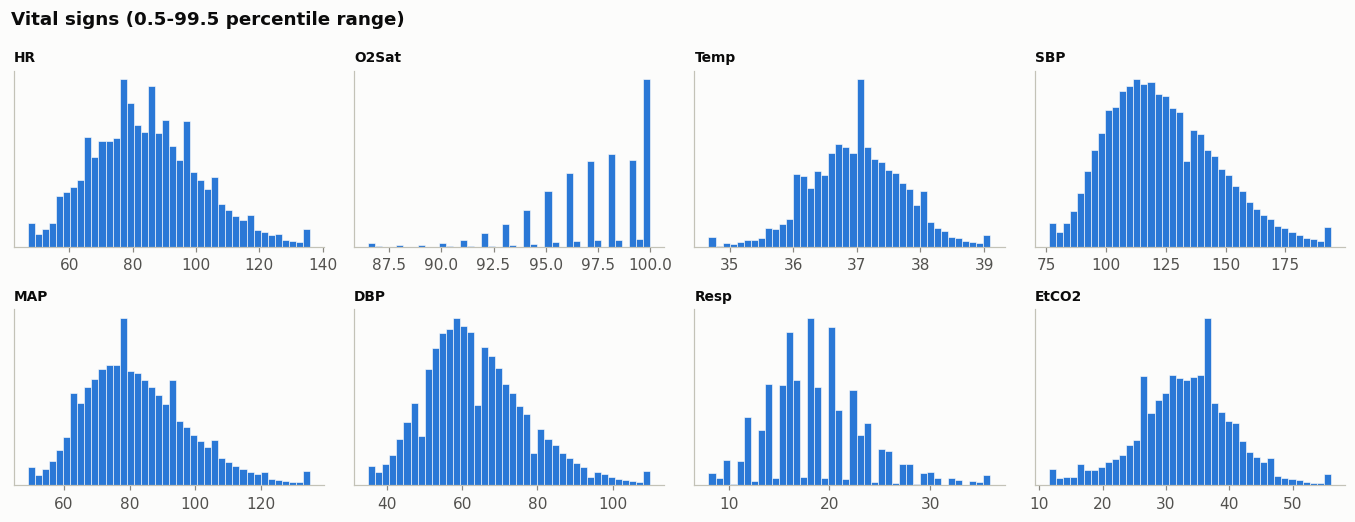

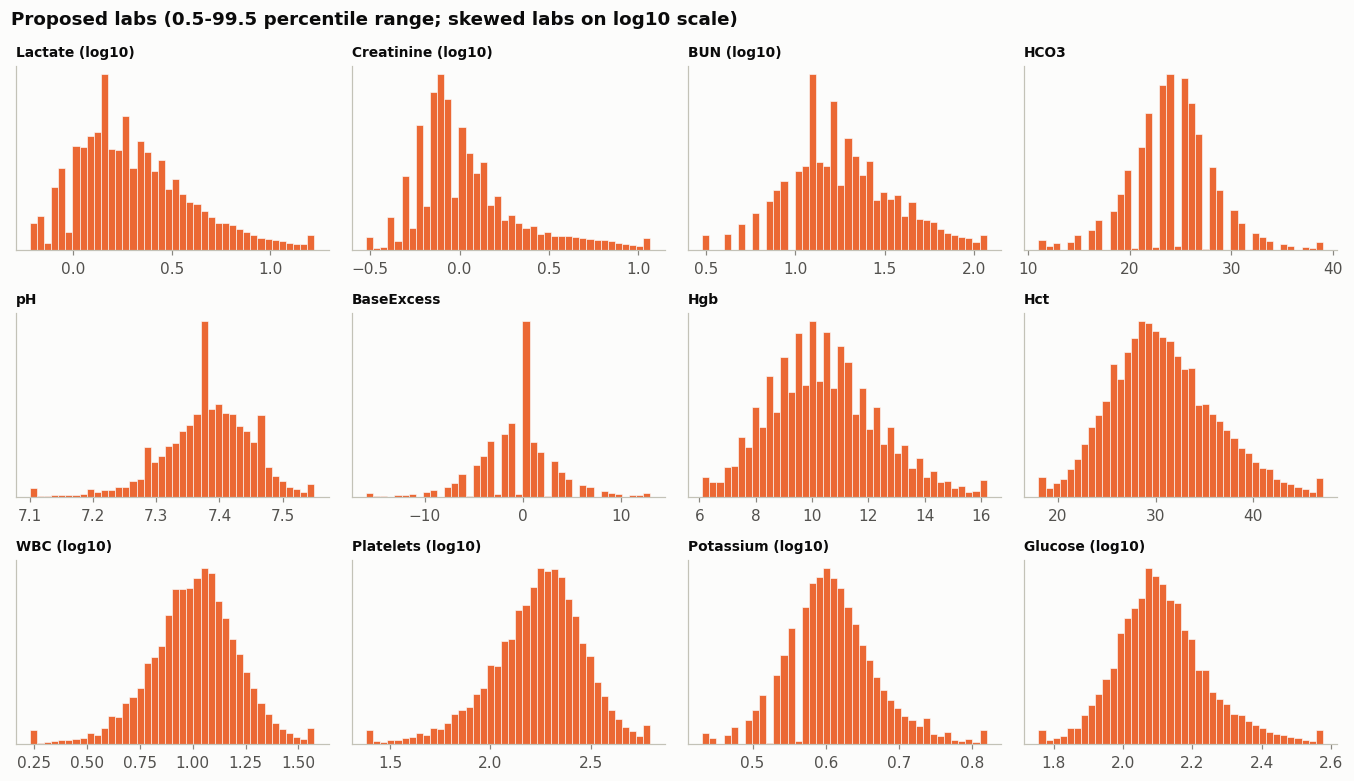

In [20]:
def hist_grid(variables, color, name, title, ncols=4):
    nrows = int(np.ceil(len(variables) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.1 * ncols, 2.4 * nrows))
    for ax, v in zip(axes.ravel(), variables):
        x = df[v].dropna()
        if len(x) == 0:
            ax.set_title(f"{v} (no data)"); continue
        lo, hi = x.quantile([0.005, 0.995])
        x = x.clip(lo, hi)
        log = bool(desc.loc[v, "suggest_log"])
        if log:
            x = np.log10(x[x > 0])
        ax.hist(x, bins=40, color=color, edgecolor=SURFACE, linewidth=0.4)
        ax.set_title(f"{v}{' (log10)' if log else ''}", fontsize=9)
        ax.set_yticks([])
        ax.grid(False)
    for ax in axes.ravel()[len(variables):]:
        ax.axis("off")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    finish(fig, name)

hist_grid(VITALS, GROUP_COLORS["Vital sign"], "10_hist_vitals",
          "Vital signs (0.5-99.5 percentile range)")
hist_grid(PROPOSED_LABS, GROUP_COLORS["Laboratory"], "11_hist_proposed_labs",
          "Proposed labs (0.5-99.5 percentile range; skewed labs on log10 scale)")

In [21]:
# Do set A and set B patients look alike? (median of each proposed numeric feature)
cont = [v for v in PROPOSED if v not in ("Gender", "Unit1", "Unit2")]
med_ab = df.groupby("set")[cont].median().T
med_ab.columns = [f"median_set_{c}" for c in med_ab.columns]
save_table(med_ab, "12_medians_A_vs_B")
display(med_ab)

demo = pd.DataFrame({
    "patients": stay.groupby("set").size(),
    "age_median": stay.groupby("set")["age"].median(),
    "age_65plus_pct": stay.groupby("set")["age"].apply(lambda a: 100 * (a >= 65).mean()),
    "male_pct": df.groupby(["set", "patient_id"])["Gender"].first().groupby(level=0).mean() * 100,
    "MICU_pct": df.groupby(["set", "patient_id"])["Unit1"].max().groupby(level=0).mean() * 100,
    "SICU_pct": df.groupby(["set", "patient_id"])["Unit2"].max().groupby(level=0).mean() * 100,
})
save_table(demo, "13_demographics_by_set")
display(demo)
print("Note: Unit1/Unit2 can both be missing for a patient; the % above are among patients with a value.")

,median_set_A,median_set_B
HR,84.00,83.00
O2Sat,98.00,98.00
Temp,37.06,36.90
SBP,118.50,124.00
MAP,77.00,84.00
DBP,58.50,65.00
Resp,18.00,18.00
Lactate,1.80,1.97
Creatinine,0.90,0.99
BUN,18.00,17.00


,patients,age_median,age_65plus_pct,male_pct,MICU_pct,SICU_pct
set,,,,,,
A,20336,64.67,49.27,58.19,49.42,50.58
B,20000,62.00,44.52,53.66,49.79,50.21


Note: Unit1/Unit2 can both be missing for a patient; the % above are among patients with a value.


## 7. Forecast target: MAP

### 7.1 Distribution and hypotension rates

,% of MAP hours below,% of patients ever below
MAP < 65,11.27,54.81
MAP < 60,4.66,35.15


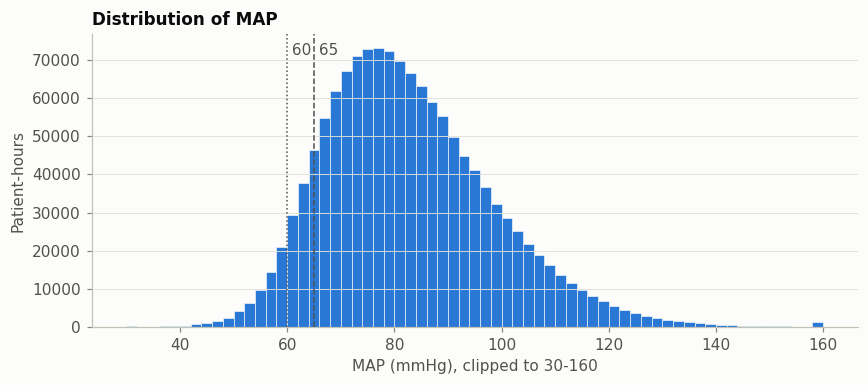

In [22]:
map_obs = df["MAP"].dropna()
pat_min = df.groupby("patient_id")["MAP"].min().dropna()
hypo = pd.DataFrame({
    "% of MAP hours below": {t: 100 * (map_obs < t).mean() for t in THRESHOLDS},
    "% of patients ever below": {t: 100 * (pat_min < t).mean() for t in THRESHOLDS},
})
hypo.index = [f"MAP < {t}" for t in THRESHOLDS]
save_table(hypo, "14_hypotension_rates")
display(hypo)

fig, ax = plt.subplots(figsize=(8, 3.6))
x = map_obs.clip(30, 160)
ax.hist(x, bins=np.arange(30, 161, 2), color=SERIES[0], edgecolor=SURFACE, linewidth=0.4)
for t, ls in zip(THRESHOLDS, ["--", ":"]):
    ax.axvline(t, color=INK2, lw=1, ls=ls)
    ax.text(t, ax.get_ylim()[1] * 0.97, f" {t}", color=INK2, va="top")
ax.set_xlabel("MAP (mmHg), clipped to 30-160")
ax.set_ylabel("Patient-hours")
ax.set_title("Distribution of MAP")
ax.grid(axis="x", visible=False)
finish(fig, "14_map_distribution")

### 7.2 Is MAP consistent with SBP and DBP?

MAP is approximately DBP + (SBP - DBP) / 3. Large disagreement can reveal measurement artifacts; hours where MAP is missing but SBP and DBP are present could be filled with this formula.

In [23]:
all3 = df[["MAP", "SBP", "DBP"]].notna().all(axis=1)
calc = df["DBP"] + (df["SBP"] - df["DBP"]) / 3
diff = (df.loc[all3, "MAP"] - calc[all3])
print(f"Hours with MAP, SBP and DBP all recorded: {all3.mean():.1%}")
print(f"MAP - formula: median {diff.median():.1f}, median |diff| {diff.abs().median():.1f}, "
      f"|diff| > 15 mmHg in {(diff.abs() > 15).mean():.1%} of those hours")
fillable = df["MAP"].isna() & df["SBP"].notna() & df["DBP"].notna()
print(f"Hours with MAP missing but SBP and DBP present: {fillable.mean():.1%} of all hours")

Hours with MAP, SBP and DBP all recorded: 68.1%
MAP - formula: median 0.0, median |diff| 2.7, |diff| > 15 mmHg in 1.5% of those hours
Hours with MAP missing but SBP and DBP present: 0.6% of all hours


### 7.3 Within-patient correlation of MAP

This motivates our models:

- **Raw lag correlation** corr(MAP_t, MAP_{t+k}) pooled over patients. If it levels off at a positive value instead of going to zero, part of the correlation is a persistent patient-level component, the **random intercept** (M1). The **ICC** estimates that level: the share of MAP variance that is between patients.
- **Within-patient lag correlation** (after removing each patient's mean). If it decays roughly geometrically with the lag, an **AR(1)** structure (M2) is reasonable.

Removing each patient's mean slightly biases the within-patient correlation downward for short stays, so read it as a shape, not an exact value.

Between-patient SD = 12.3 mmHg; within-patient SD = 11.0 mmHg; ICC = 0.56
Lag-1 within-patient correlation = 0.41


,pairs,raw_corr,within_corr
lag_h,,,
1,1233888,0.74,0.41
2,1211212,0.69,0.29
3,1162219,0.66,0.23
4,1138487,0.64,0.17
5,1091745,0.62,0.13
6,1064224,0.60,0.09
7,1022825,0.59,0.06
8,996184,0.58,0.04
9,955215,0.57,0.02


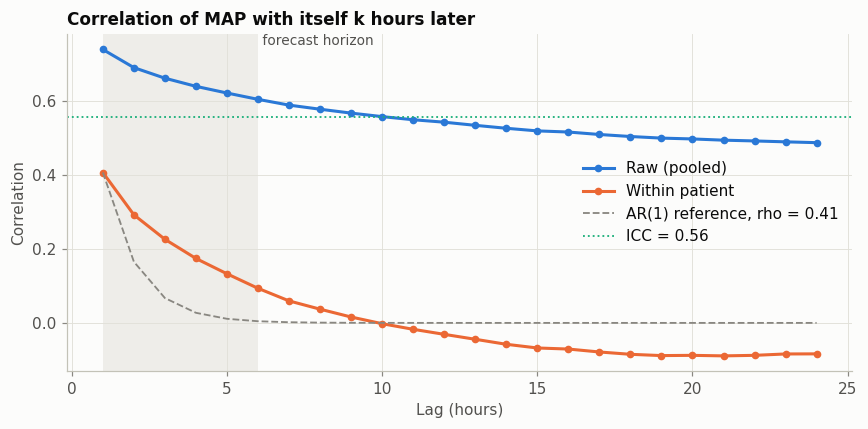

In [24]:
g = df.groupby("patient_id")["MAP"]
map_c = df["MAP"] - g.transform("mean")
gc = map_c.groupby(df["patient_id"])
lags = np.arange(1, 25)
lag_rows = []
for k in lags:
    fut = g.shift(-k)
    fut_c = gc.shift(-k)
    ok = (df["MAP"].notna() & fut.notna()).to_numpy()
    lag_rows.append({"lag_h": k, "pairs": int(ok.sum()),
                     "raw_corr": np.corrcoef(df["MAP"].to_numpy()[ok], fut.to_numpy()[ok])[0, 1],
                     "within_corr": np.corrcoef(map_c.to_numpy()[ok], fut_c.to_numpy()[ok])[0, 1]})
lagcorr = save_table(pd.DataFrame(lag_rows).set_index("lag_h"), "15_map_lag_correlation")

pm = df.groupby("patient_id")["MAP"].agg(["mean", "var", "count"]).dropna()
pm = pm[pm["count"] >= 2]
sigma_w2 = np.average(pm["var"], weights=pm["count"] - 1)
sigma_b2 = max(pm["mean"].var() - sigma_w2 * (1 / pm["count"]).mean(), 0.0)
icc = sigma_b2 / (sigma_b2 + sigma_w2)
rho1 = lagcorr.loc[1, "within_corr"]
print(f"Between-patient SD = {np.sqrt(sigma_b2):.1f} mmHg; within-patient SD = {np.sqrt(sigma_w2):.1f} mmHg; "
      f"ICC = {icc:.2f}")
print(f"Lag-1 within-patient correlation = {rho1:.2f}")
display(lagcorr.head(12))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lagcorr.index, lagcorr["raw_corr"], color=SERIES[0], marker="o", ms=4, label="Raw (pooled)")
ax.plot(lagcorr.index, lagcorr["within_corr"], color=SERIES[1], marker="o", ms=4, label="Within patient")
ax.plot(lags, rho1 ** lags, color=MUTED, lw=1.2, ls="--", label=f"AR(1) reference, rho = {rho1:.2f}")
ax.axhline(icc, color=SERIES[2], lw=1.2, ls=":", label=f"ICC = {icc:.2f}")
ax.axvspan(1, HORIZON, color=GRID, alpha=0.5, lw=0)
ax.text(HORIZON, ax.get_ylim()[1], " forecast horizon", color=INK2, va="top", fontsize=9)
ax.set_xlabel("Lag (hours)")
ax.set_ylabel("Correlation")
ax.set_title("Correlation of MAP with itself k hours later")
ax.legend(loc="center right")
finish(fig, "15_map_lag_correlation")

### 7.4 How many forecast windows will we have?

A forecast origin is an hour `t` with observed MAP at or above the threshold. Window types:

- **complete**: all 6 future hours have MAP (our starting point for training)
- **any**: at least one future hour has MAP (usable once we marginalize the Gaussian over missing hours)

Event = MAP below the threshold at least once in the next 6 hours; "sustained" = below for 2 consecutive hours. The age-specific row uses 60 mmHg for patients aged 65 or older and 65 mmHg otherwise.

In [25]:
fut = pd.concat({h: g.shift(-h) for h in range(1, HORIZON + 1)}, axis=1)
n_future = fut.notna().sum(axis=1)
fut_min = fut.min(axis=1)
cur = df["MAP"]
age_thr = np.where(df["Age"] >= 65, 60, 65)

def window_stats(threshold, label):
    thr = pd.Series(threshold, index=df.index) if np.ndim(threshold) else pd.Series(float(threshold), index=df.index)
    below = fut.lt(thr, axis=0)
    sustained = pd.concat([below[h] & below[h + 1] for h in range(1, HORIZON)], axis=1).any(axis=1)
    out = []
    for wtype, wmask in [("complete", n_future == HORIZON), ("any", n_future >= 1)]:
        for s in ["A", "B", "All"]:
            m = cur.notna() & (cur >= thr) & wmask
            if s != "All":
                m &= df["set"] == s
            out.append({"threshold": label, "window": wtype, "set": s,
                        "windows": int(m.sum()), "patients": df.loc[m, "patient_id"].nunique(),
                        "event_pct": 100 * (fut_min[m] < thr[m]).mean() if m.any() else np.nan,
                        "sustained_event_pct": 100 * sustained[m].mean() if m.any() else np.nan})
    return out

rows = []
for t in THRESHOLDS:
    rows += window_stats(t, f"MAP < {t}")
rows += window_stats(age_thr, "age-specific (60 if age >= 65, else 65)")
windows = save_table(pd.DataFrame(rows).set_index(["threshold", "window", "set"]), "16_forecast_windows")
display(windows)

windows  patients  event_pct  sustained_event_pct
threshold                               window   set                                                   
MAP < 65                                complete A     395043     19404      29.48                11.95
                                                 B     373117     17820      14.70                 4.71
                                                 All   768160     37224      22.30                 8.43
                                        any      A     580827     20259      26.44                 9.98
                                                 B     587435     19716      13.09                 3.86
                                                 All  1168262     39975      19.73                 6.90
MAP < 60                                complete A     437642     19520      16.20                 4.93
                                                 B     390282     17863       6.53                 1.59
                                                 All   827924     37383      11.64                 3.36
                                        any      A     641827     20302      14.59                 4.16
                                                 B     613659     19731       5.81                 1.31
                                                 All  1255486     40033      10.29                 2.77
age-specific (60 if age >= 65, else 65) complete A     421577     19465      21.60                 7.53
                                                 B     382715     17846      10.28                 2.99
                                                 All   804292     37311      16.22                 5.37
                                        any      A     618206     20279      19.54                 6.35
                                                 B     601907     19726       9.22                 2.47
                                                 All  1220113     40005      14.45                 4.44

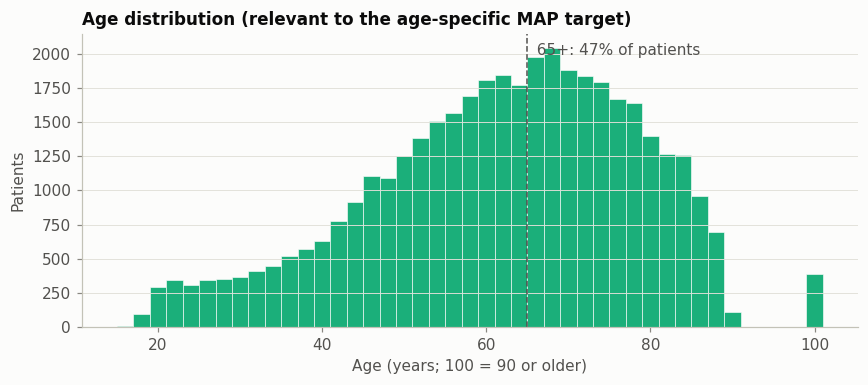

Patients coded as 100 (age 90+): 1.0%


In [26]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ages = stay["age"].dropna()
ax.hist(ages, bins=np.arange(15, 102, 2), color=SERIES[2], edgecolor=SURFACE, linewidth=0.4)
ax.axvline(65, color=INK2, lw=1, ls="--")
ax.text(65, ax.get_ylim()[1] * 0.97, f"  65+: {100 * (ages >= 65).mean():.0f}% of patients", color=INK2, va="top")
ax.set_xlabel("Age (years; 100 = 90 or older)")
ax.set_ylabel("Patients")
ax.set_title("Age distribution (relevant to the age-specific MAP target)")
ax.grid(axis="x", visible=False)
finish(fig, "17_age_distribution")
print(f"Patients coded as 100 (age 90+): {100 * (ages == 100).mean():.1f}%")

## 8. Summary

Key numbers for the report; also saved as `summary.json` in `OUT_DIR`.

In [27]:
def wcount(thr_label, wtype="complete", s="All"):
    return int(windows.loc[(thr_label, wtype, s), "windows"])

summary = {
    "patients": int(overview.loc["patients", "All"]),
    "patients_set_A": int(overview.loc["patients", "Set A"]),
    "patients_set_B": int(overview.loc["patients", "Set B"]),
    "patient_hours": int(overview.loc["patient_hours", "All"]),
    "median_hours_per_patient": float(overview.loc["median_hours", "All"]),
    "sepsis_pct": round(float(overview.loc["sepsis_pct", "All"]), 2),
    "variables_above_missing_cutoff": flagged,
    "proposed_features_above_cutoff": [v for v in flagged if v in PROPOSED],
    "labs_suggested_log": desc.index[desc["suggest_log"]].tolist(),
    "MAP_missing_pct": round(float(miss.loc["MAP", "missing_pct_all"]), 2),
    "pct_MAP_hours_below_65": round(float(hypo.iloc[0, 0]), 2),
    "map_icc": round(float(icc), 3),
    "map_lag1_within_corr": round(float(rho1), 3),
    "complete_windows_MAP65": wcount(f"MAP < {THRESHOLDS[0]}"),
    "event_pct_complete_MAP65": round(float(windows.loc[(f"MAP < {THRESHOLDS[0]}", "complete", "All"), "event_pct"]), 2),
}
(OUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
for k, v in summary.items():
    print(f"{k:35s} {v}")
print("\nTables and figures saved in", OUT_DIR.resolve())

patients                            40336
patients_set_A                      20336
patients_set_B                      20000
patient_hours                       1552210
median_hours_per_patient            38.0
sepsis_pct                          7.27
variables_above_missing_cutoff      ['Chloride', 'HCO3', 'Phosphate', 'EtCO2', 'SaO2', 'PTT', 'Lactate', 'AST', 'Alkalinephos', 'Bilirubin_total', 'TroponinI', 'Fibrinogen', 'Bilirubin_direct']
proposed_features_above_cutoff      ['HCO3', 'Lactate']
labs_suggested_log                  ['PaCO2', 'AST', 'BUN', 'Alkalinephos', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'PTT', 'WBC', 'Fibrinogen', 'Platelets']
MAP_missing_pct                     12.45
pct_MAP_hours_below_65              11.27
map_icc                             0.555
map_lag1_within_corr                0.406
complete_windows_MAP65              768160
event_pct_complete_MAP65            22.3

T

### How to read the results

- **Feature list.** Drop or rethink proposed features flagged above the missingness cutoff; keep masks and time-since-last for the rest (`median_hours_between_obs` shows how stale a forward-filled lab typically is).
- **Set A vs B.** Large missingness or median differences mean set B is a real distribution shift, which makes the external validation more informative.
- **Log transforms.** Use the `suggest_log` column.
- **Random effect vs AR(1).** A clearly positive ICC and a raw lag correlation that levels off support M1; a within-patient correlation that decays like the AR(1) reference supports M2; seeing both supports M3.
- **Sample size and events.** The forecast-window table gives the number of training windows and the hypotension event rate, which tells us whether AUPRC will be dominated by rare events.